# Tema : Modelos ARIMAX
![](src/img/logo_utb.png){width=40%}
![](src/img/logo_etd.png){width=40%}
- **Profesor:**
- **Fernando Salcedo Mejía, Eco Msc.**
- Programa de Ciencias de Datos | Escuela de transformación digital.
- 2026-1

## Ejemplo 1 : El modelo macroeconómico del crecimiento del consumo en Estados Unidos

- Queremos modelar cómo cambia el consumo real (compra de bienes y servicios) de una economía según el incremento del ingreso.
$$
\Delta C_t = \beta_0 + \beta_1 \Delta Ingreso_t + \eta_t
$$

- $\Delta C_t$ es el cambio porcentual en el gasto real de consumo personal.
- $Ingreso_t$ es el cambio porcentual en el ingreso personal real disponible.
- $\eta_t$ es el error de la regresión, que sigue un proceso $ARMA(p, q)$.

- Usar el archivo `US_change.csv` para modelar.

In [1]:
# Instalar todas las librerias necesarias previamente desde r-requirements.txt
suppressPackageStartupMessages({
  library(tidyverse)
  library(fable)       # Modelos ARIMA con regresoras (ARIMAX)
  library(feasts)      # ACF, PACF
  library(tsibble)     # Estructura de datos para series de tiempo
  library(ggtime)      # Visualización
  library(tseries)     # Pruebas ADF y KPSS
  library(patchwork)   # Combinar gráficos
})

# tamaño de los graficos
options(repr.plot.width = 8,
        repr.plot.height = 6,
        repr.plot.res = 300,
        repr.plot.pointsize = 14)

set_theme(theme_bw())

# leer y ajustar datos
us_change <- read_csv("../data/US_change.csv", show_col_types = FALSE) |>
  mutate(ds = yearquarter(ds)) |>   # Configurar el tiempo de la serie trimestral
  rename(Consumo = y, Ingreso = Income) |>
  as_tsibble(index = ds)

# Encabezado
head(us_change)

ds,Consumo,Ingreso,Production,Savings,Unemployment,unique_id
<qtr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1970 Q1,0.6185664,1.0448013,-2.4524855,5.299014,0.9,US_change
1970 Q2,0.4519840,1.2256472,-0.5514595,7.789894,0.5,US_change
1970 Q3,0.8728718,1.5851538,-0.3586518,7.403984,0.5,US_change
1970 Q4,-0.2718479,-0.2395449,-2.1856909,1.169898,0.7,US_change
1971 Q1,1.9013450,1.9759249,1.9097644,3.535667,-0.1,US_change
1971 Q2,0.9148773,1.4459085,0.9015695,5.874764,-0.1,US_change


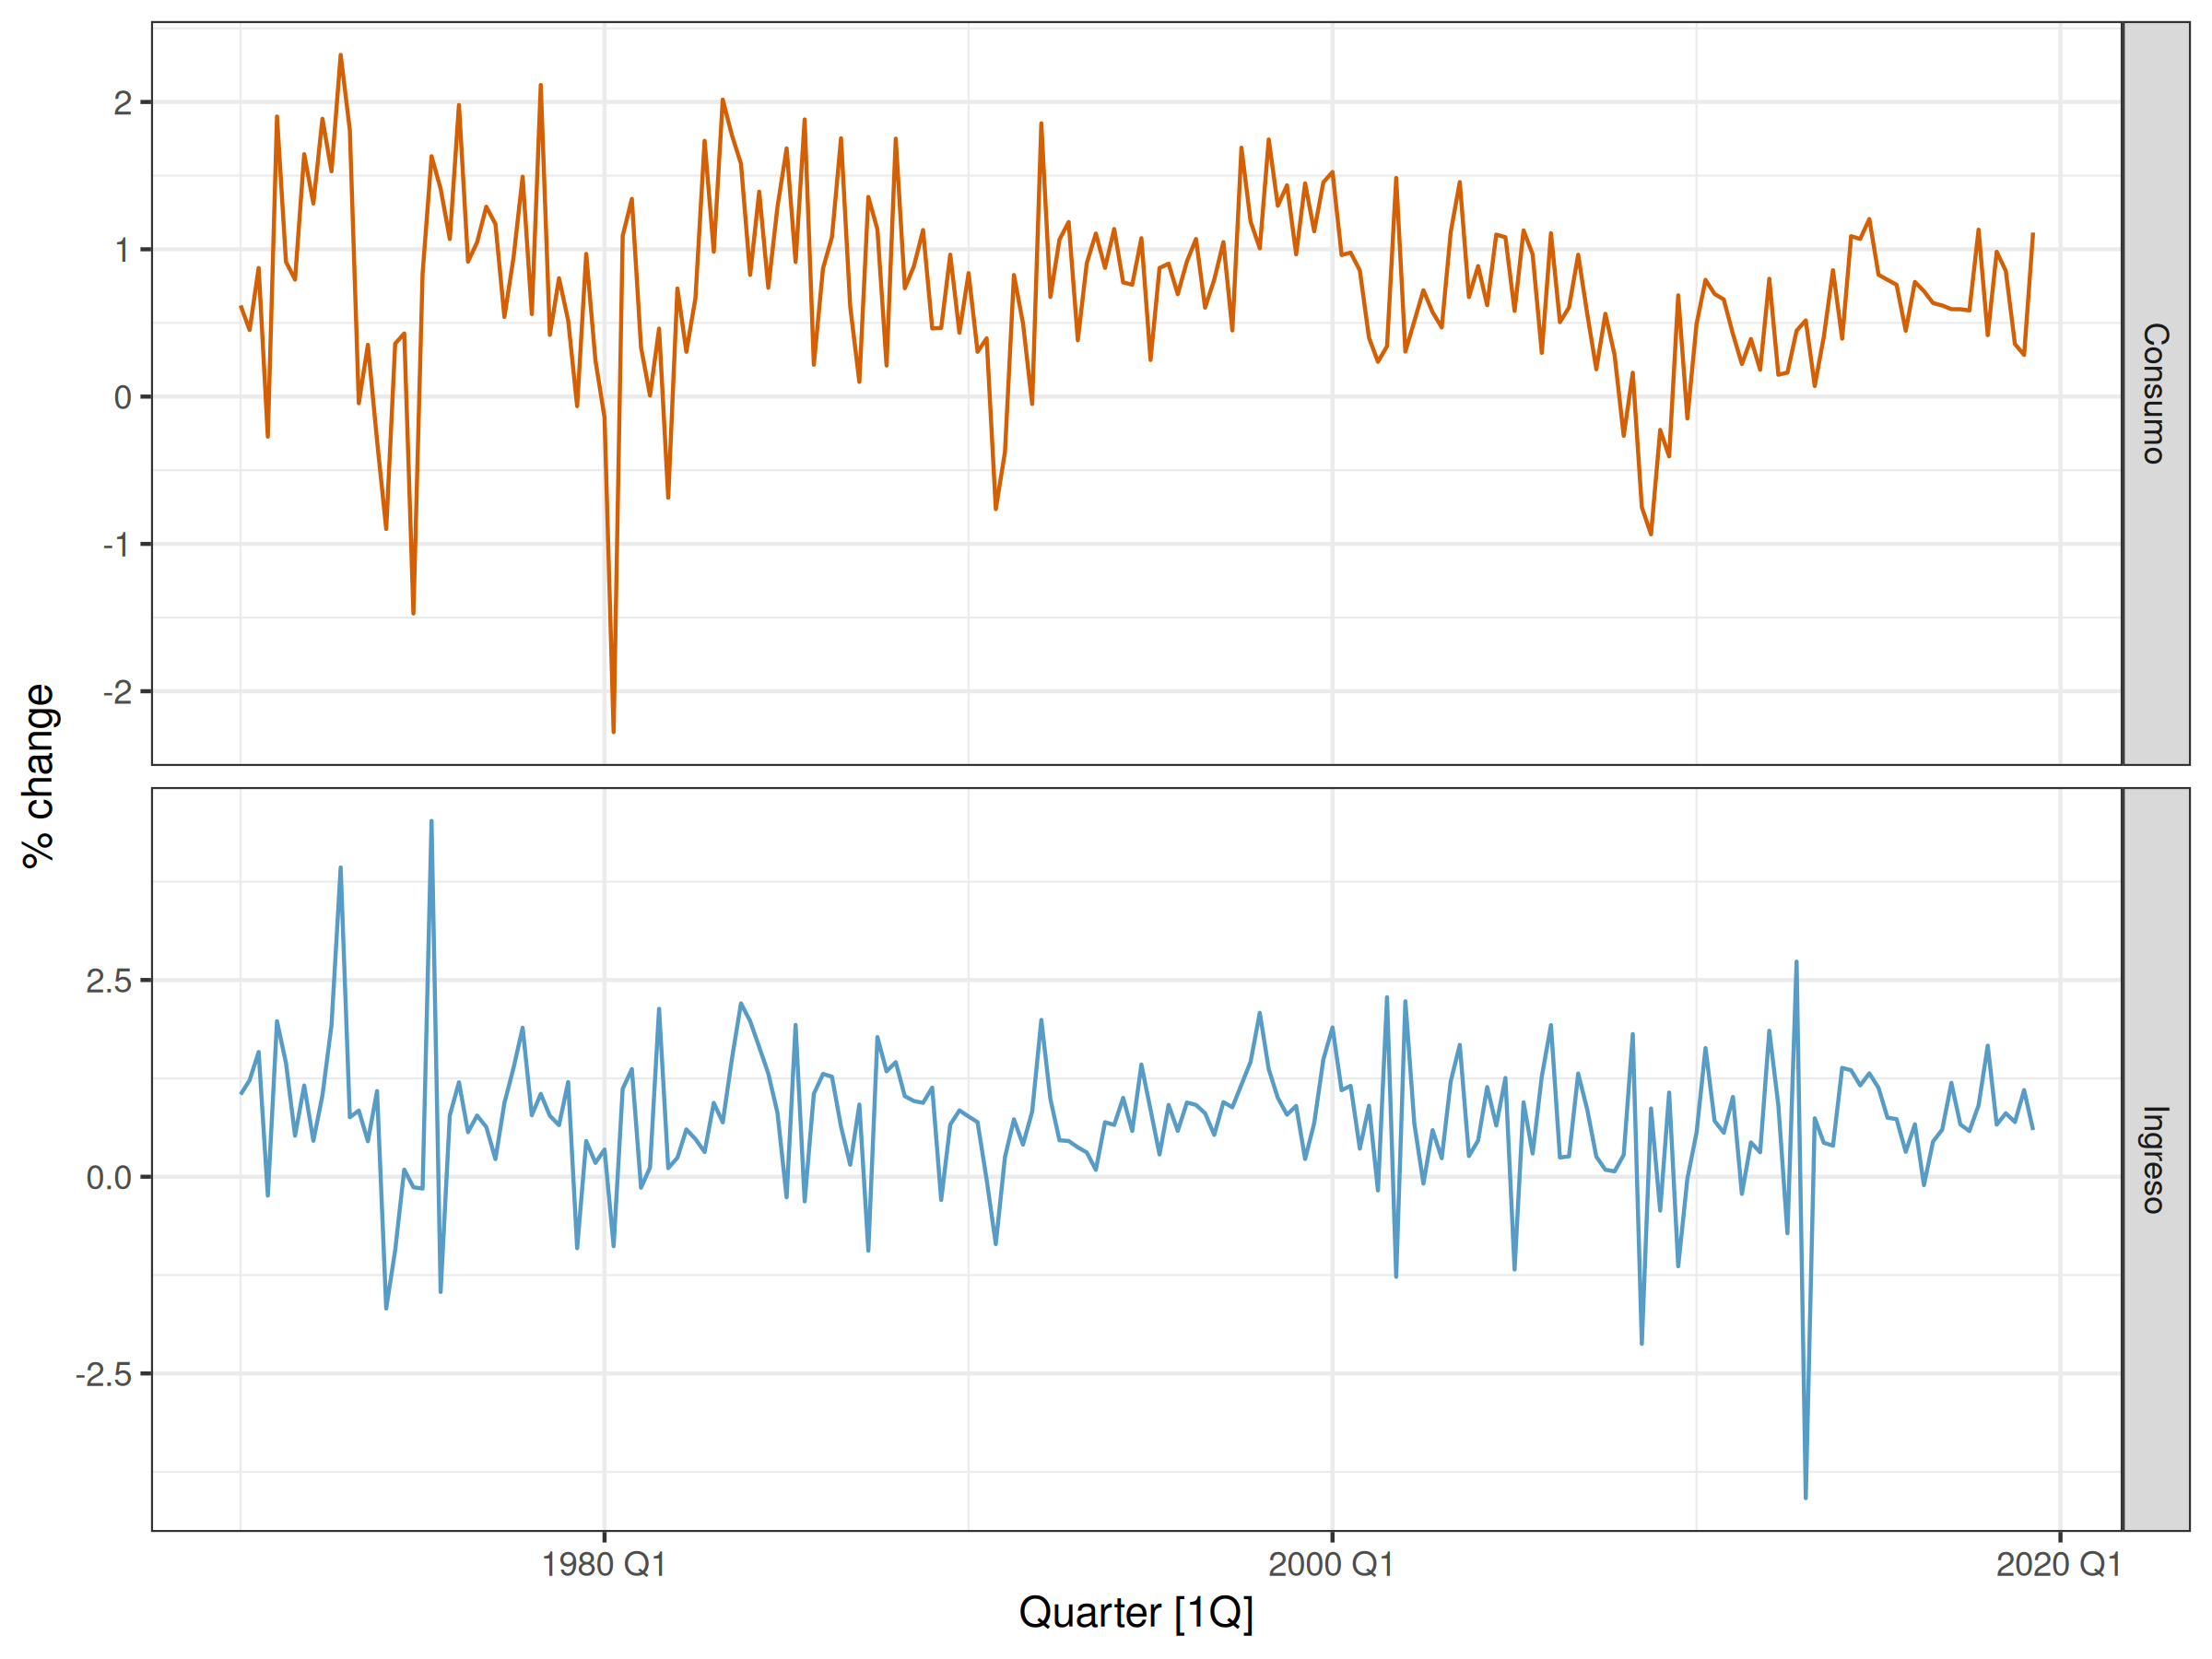

In [2]:
us_change |>
  pivot_longer(c(Consumo, Ingreso), names_to = "Serie", values_to = "valor") |>
  ggplot(aes(ds, valor, colour = Serie)) +
  geom_line() +
  facet_grid(Serie ~ ., scales = "free_y") +
  scale_colour_manual(values = c("#D55F03", "#569CC6")) +
  guides(colour = "none") +
  labs(x = "Quarter [1Q]", y = "% change")

In [3]:
test_estacionariedad <- function(datos) {
  datos <- as.numeric(na.omit(datos))
  # Augmented Dickey-Fuller (H0: la serie tiene raíz unitaria)
  adf_result  <- suppressWarnings(adf.test(datos))
  # KPSS (H0: la serie es estacionaria en nivel)
  kpss_result <- suppressWarnings(kpss.test(datos, null = "Level"))

  # Tabla de resultados
  tibble(
    Test         = c("Prueba Augmented Dickey-Fuller (ADF)", "Prueba KPSS"),
    Estadistico  = round(c(adf_result$statistic, kpss_result$statistic), 4),
    `P-valor`    = round(c(adf_result$p.value, kpss_result$p.value), 4),
    Estacionario = c(if_else(adf_result$p.value < 0.05, "Sí", "No"),
                     if_else(kpss_result$p.value < 0.05, "No", "Sí"))
  )
}


bind_rows(
  test_estacionariedad(us_change$Consumo) |> mutate(Serie = "Consumo", .before = 1),
  test_estacionariedad(us_change$Ingreso) |> mutate(Serie = "Ingreso", .before = 1)
)

Serie,Test,Estadistico,P-valor,Estacionario
<chr>,<chr>,<dbl>,<dbl>,<chr>
Consumo,Prueba Augmented Dickey-Fuller (ADF),-4.6806,0.01,Sí
Consumo,Prueba KPSS,0.2746,0.10,Sí
Ingreso,Prueba Augmented Dickey-Fuller (ADF),-6.4371,0.01,Sí
Ingreso,Prueba KPSS,0.1619,0.10,Sí


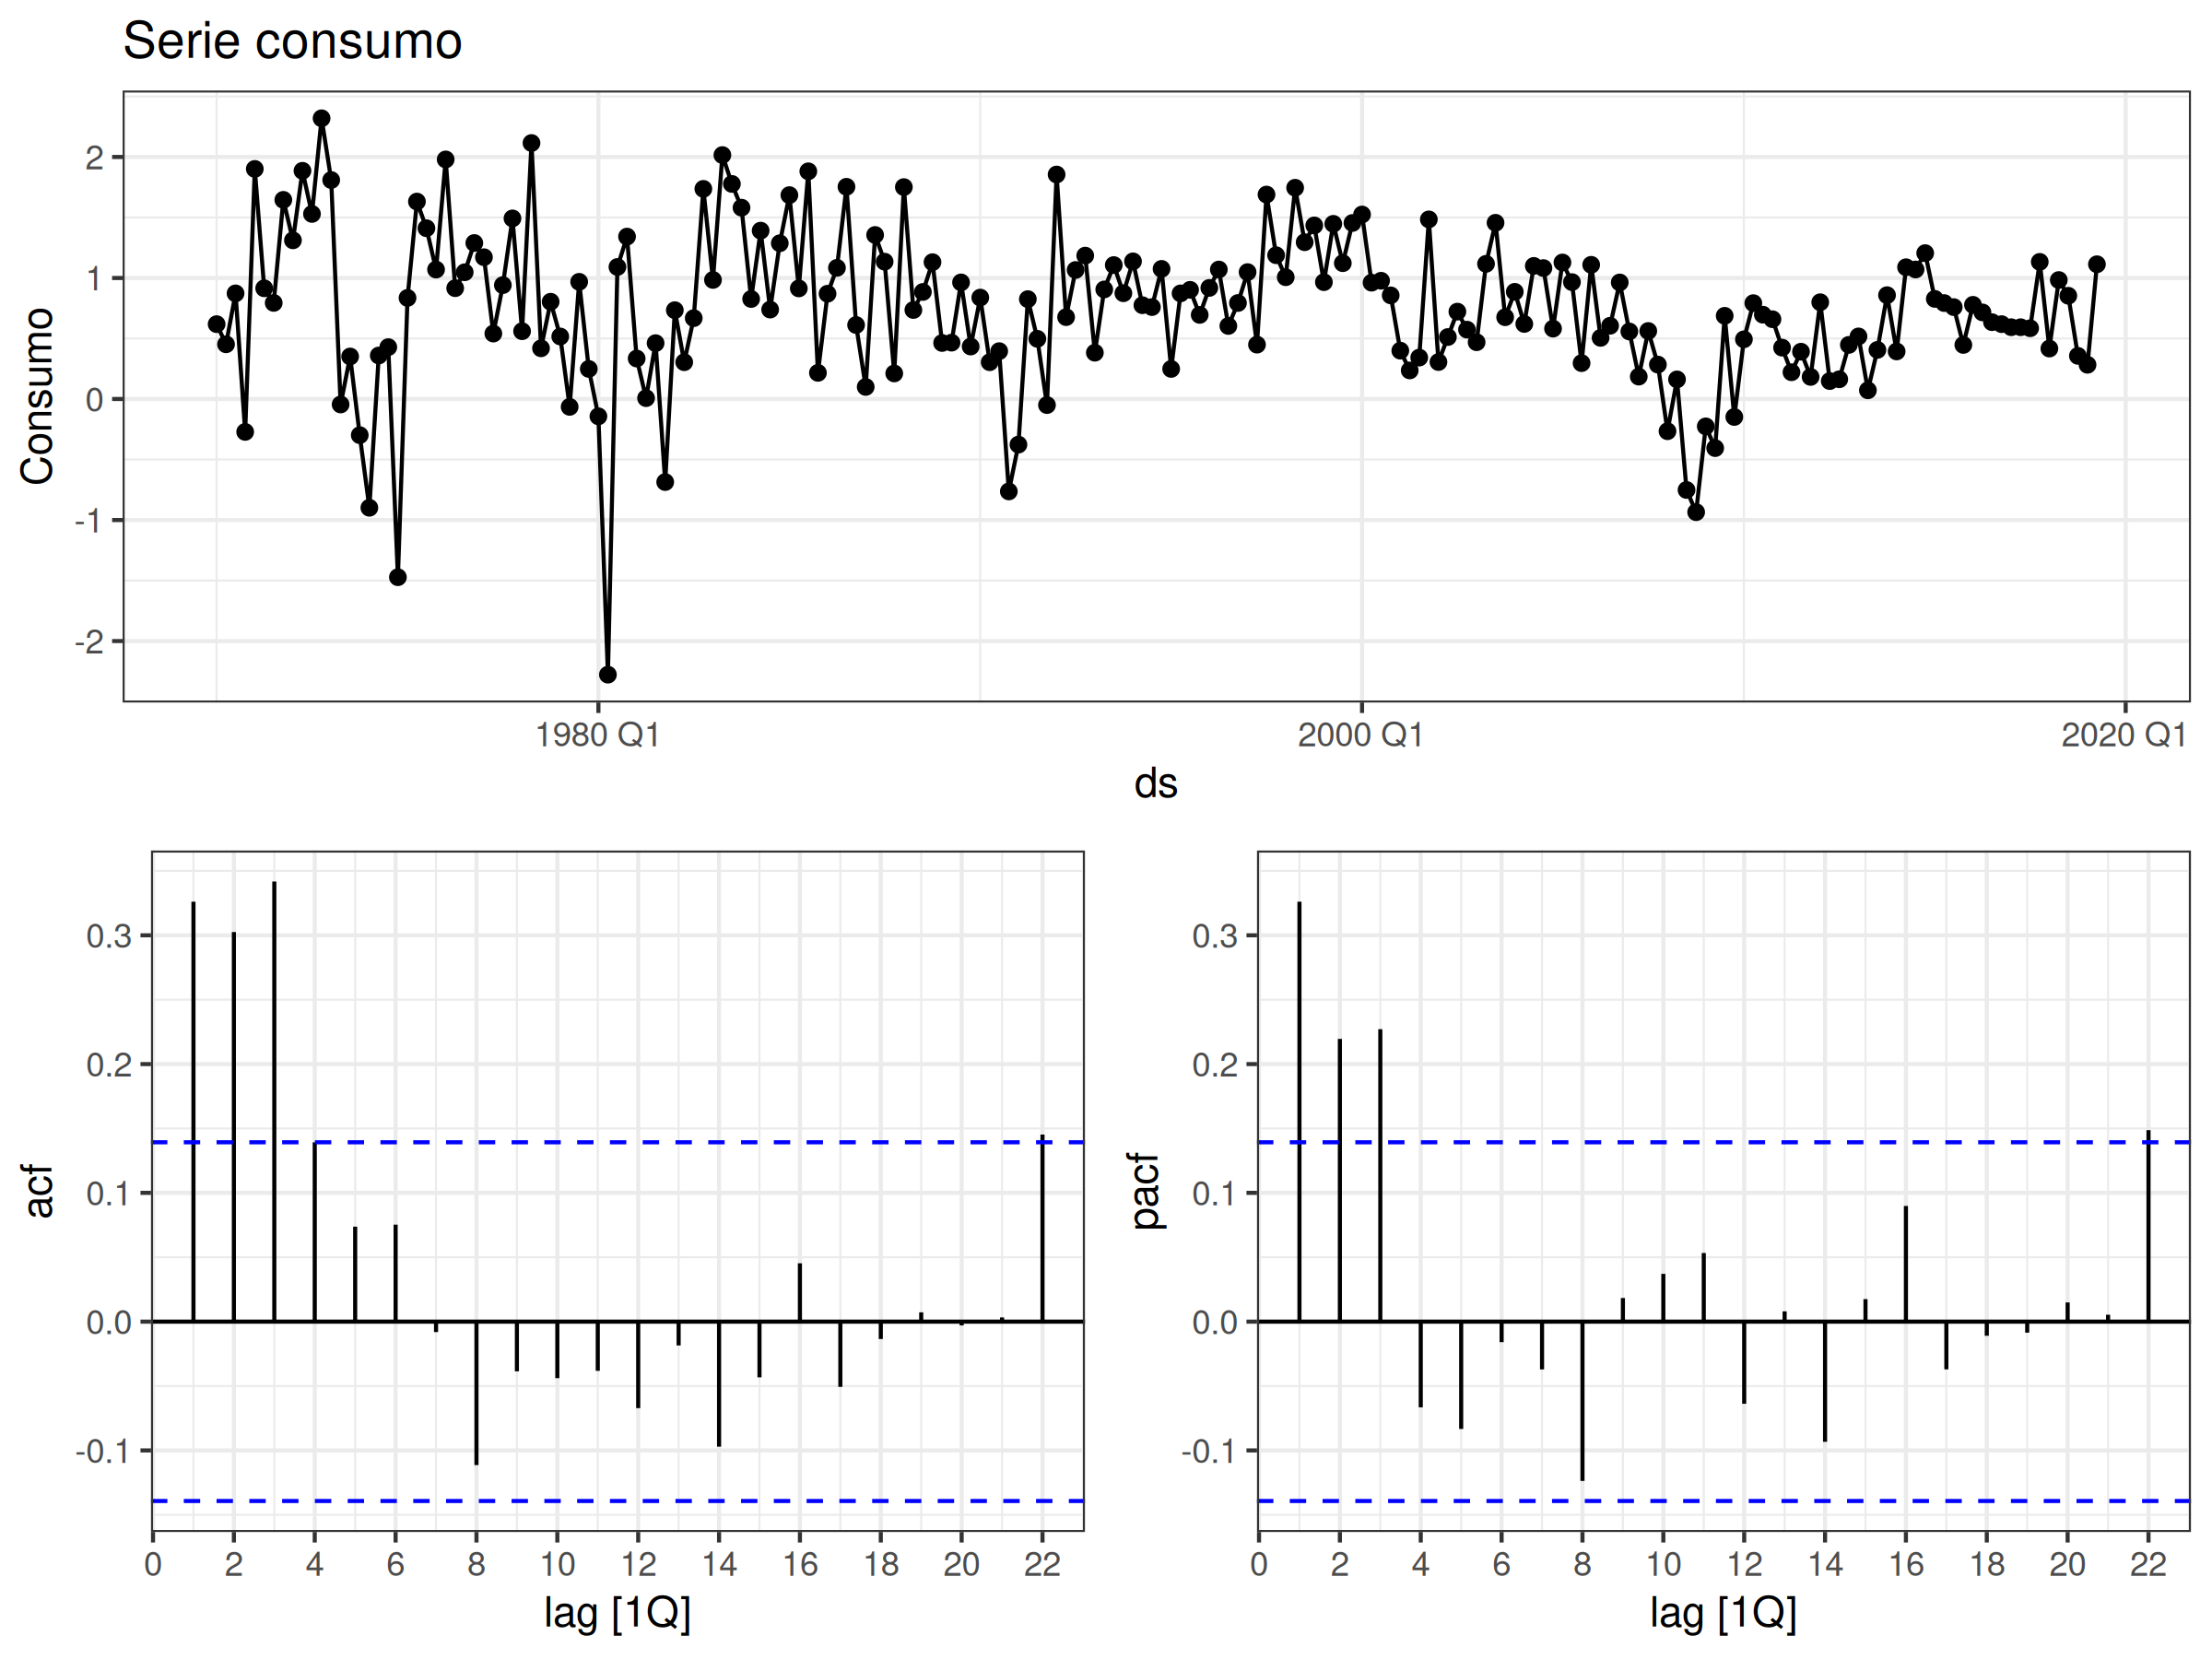

In [4]:
# Serie consumo, ACF y PACF
us_change |>
  gg_tsdisplay(Consumo, plot_type = "partial") +
  labs(title = "Serie consumo")

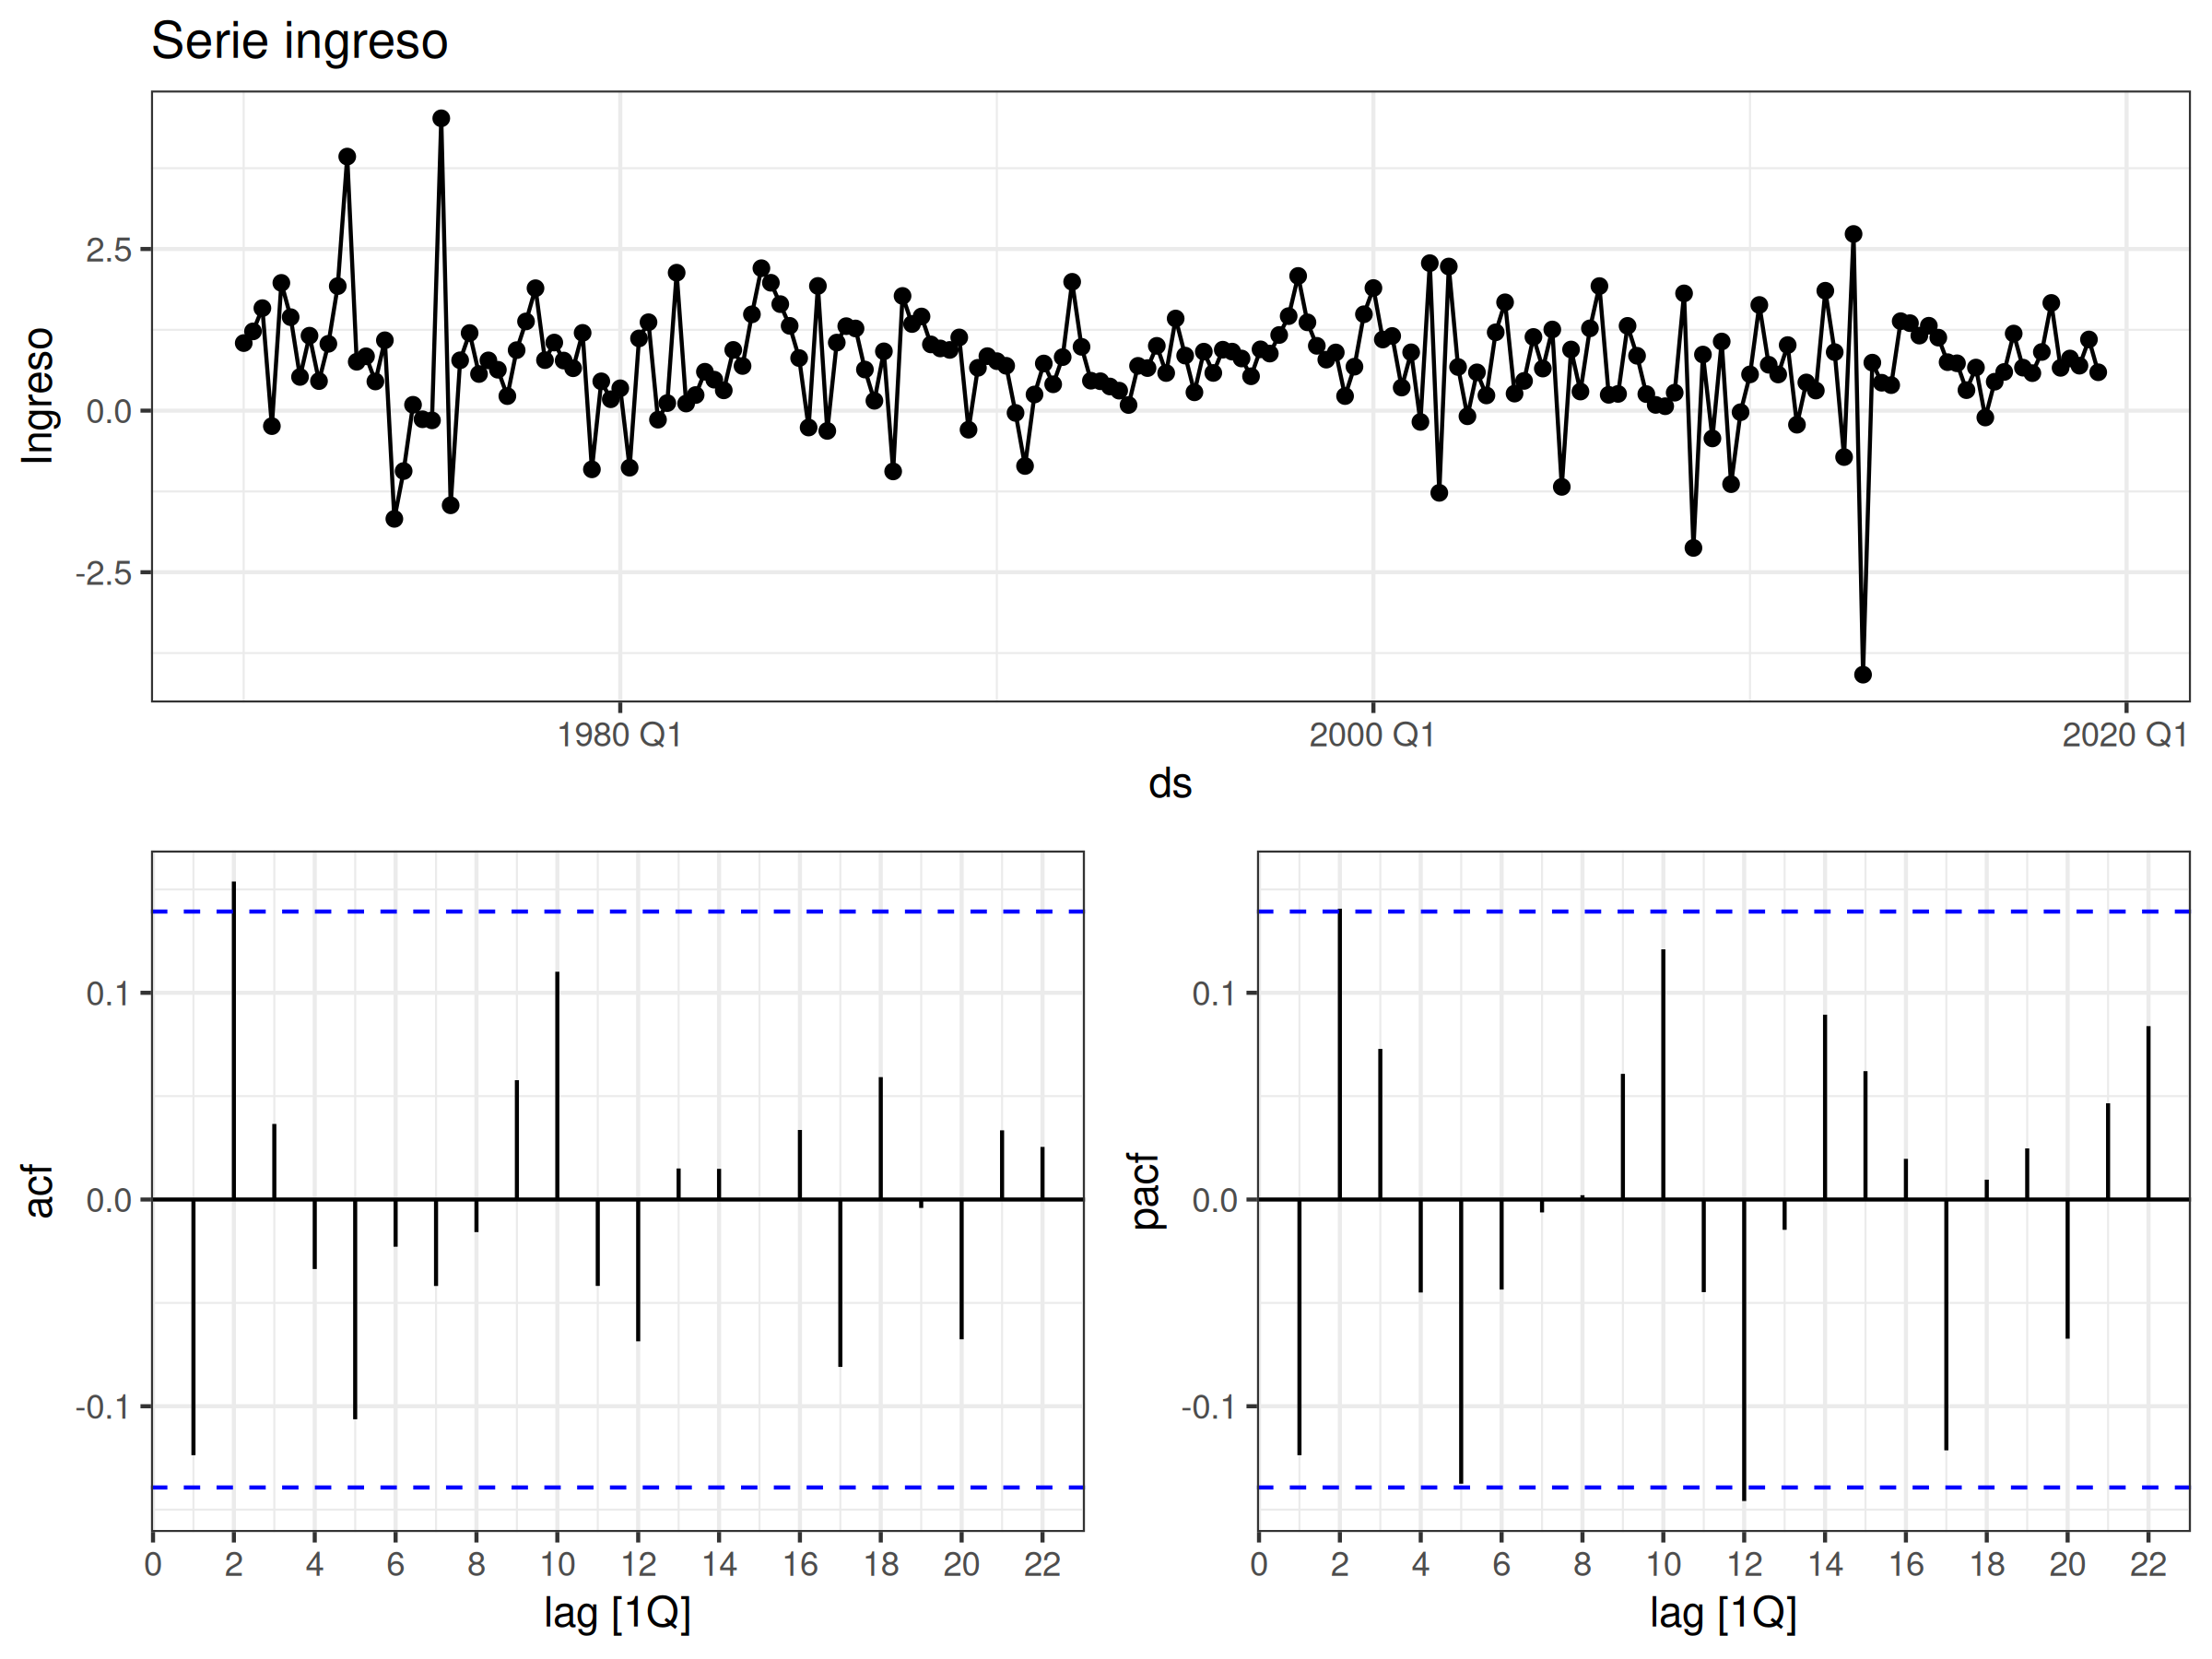

In [5]:
# Serie ingreso, ACF y PACF
us_change |>
  gg_tsdisplay(Ingreso, plot_type = "partial") +
  labs(title = "Serie ingreso")

## Estimación de modelos ARIMAX

- En `fable` las variables exógenas se agregan en la fórmula del modelo: `ARIMA(Consumo ~ Ingreso + pdq(p, d, q))`.
- El modelo estimado es una **regresión con errores ARIMA**: $C_t = \beta_0 + \beta_1 Ingreso_t + \eta_t$, con $\eta_t \sim ARMA(p, q)$.

In [6]:
modelos_consumo <- us_change |>
  model(
    `ARIMA(0,0,3)` = ARIMA(Consumo ~ Ingreso + pdq(0, 0, 3) + PDQ(0, 0, 0)),
    `ARIMA(3,0,1)` = ARIMA(Consumo ~ Ingreso + pdq(3, 0, 1) + PDQ(0, 0, 0)),
    # Autoarima: busca el mejor ARMA(p, q) para los errores de la regresión
    `auto-ARIMA`   = ARIMA(Consumo ~ Ingreso + pdq(d = 0) + PDQ(0, 0, 0),
                           stepwise = FALSE, approximation = FALSE)
  )

# ARIMA(0, 0, 3)
modelos_consumo |> select(`ARIMA(0,0,3)`) |> report()

Series: Consumo 
Model: LM w/ ARIMA(0,0,3) errors 

Coefficients:
         ma1     ma2     ma3  Ingreso  intercept
      0.1192  0.2230  0.1881   0.1848     0.6071
s.e.  0.0779  0.0692  0.0681   0.0511     0.0709

sigma^2 estimated as 0.3168:  log likelihood=-164.73
AIC=341.47   AICc=341.91   BIC=361.19


In [7]:
# ARIMA(3, 0, 1)
modelos_consumo |> select(`ARIMA(3,0,1)`) |> report()

Series: Consumo 
Model: LM w/ ARIMA(3,0,1) errors 

Coefficients:
         ar1     ar2     ar3     ma1  Ingreso  intercept
      0.0449  0.2363  0.2003  0.0662   0.1848     0.6046
s.e.  0.3276  0.0848  0.1065  0.3343   0.0490     0.0873

sigma^2 estimated as 0.3119:  log likelihood=-162.71
AIC=339.42   AICc=340   BIC=362.43


In [8]:
# ARIMA optimo
modelos_consumo |> select(`auto-ARIMA`) |> report()

# Comparación por AICc
glance(modelos_consumo) |>
  select(Modelo = .model, AIC, AICc, BIC, sigma2) |>
  arrange(AICc)

Series: Consumo 
Model: LM w/ ARIMA(3,0,0) errors 

Coefficients:
         ar1     ar2     ar3  Ingreso  intercept
      0.1081  0.2267  0.1835   0.1861     0.6035
s.e.  0.0760  0.0699  0.0707   0.0486     0.0877

sigma^2 estimated as 0.3104:  log likelihood=-162.73
AIC=337.45   AICc=337.89   BIC=357.18


Modelo,AIC,AICc,BIC,sigma2
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
auto-ARIMA,337.4537,337.8935,357.1833,0.3103616
"ARIMA(3,0,1)",339.4150,340.0045,362.4329,0.3119149
"ARIMA(0,0,3)",341.4654,341.9052,361.1950,0.3168432


.model,lb_stat,lb_pvalue
<chr>,<dbl>,<dbl>
auto-ARIMA,4.875965,0.6750967


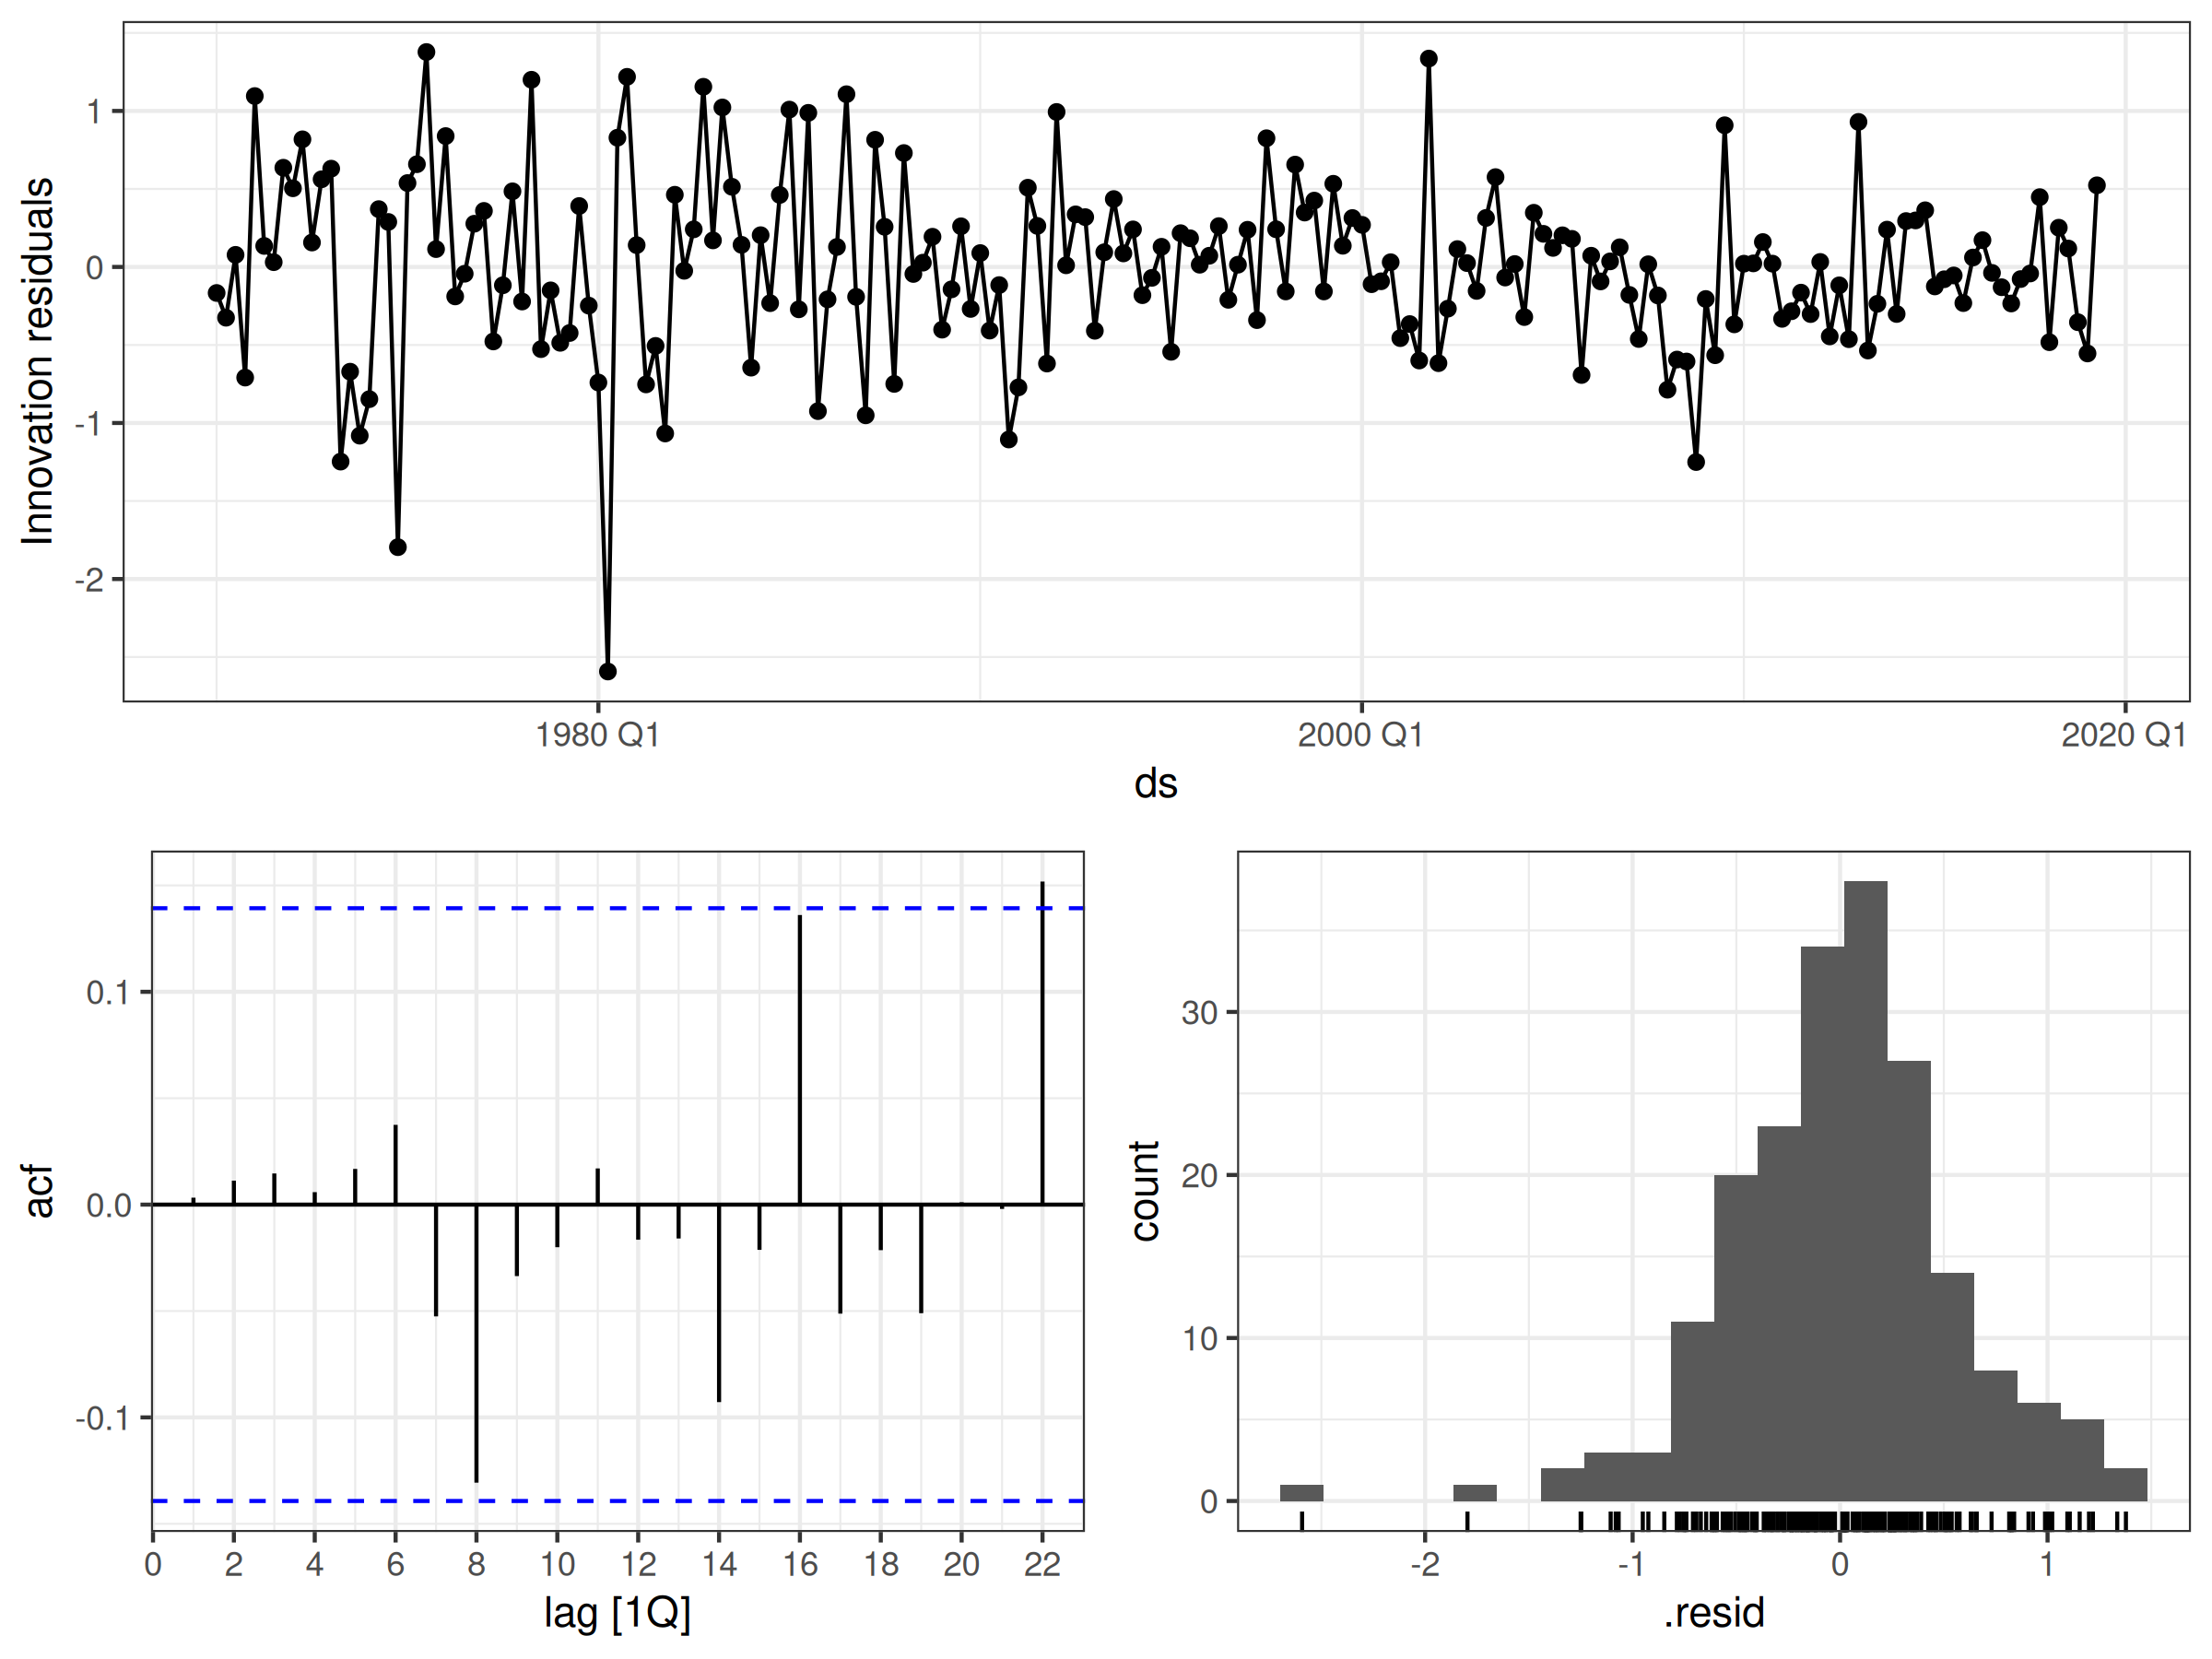

In [9]:
# Diagnóstico de los residuos del modelo óptimo
auto_arima_optimo <- modelos_consumo |> select(`auto-ARIMA`)
auto_arima_optimo |> gg_tsresiduals()

# Ljung-Box sobre los residuos de innovación
augment(auto_arima_optimo) |>
  features(.innov, ljung_box, lag = 10, dof = nrow(tidy(auto_arima_optimo)) - 2)

**Componentes del modelo**

- En una regresión con errores ARIMA hay dos tipos de residuos: los **residuos de la regresión** $\hat{\eta}_t$ (que conservan la autocorrelación) y los **residuos de innovación** $\hat{\varepsilon}_t$ (que deben ser ruido blanco).

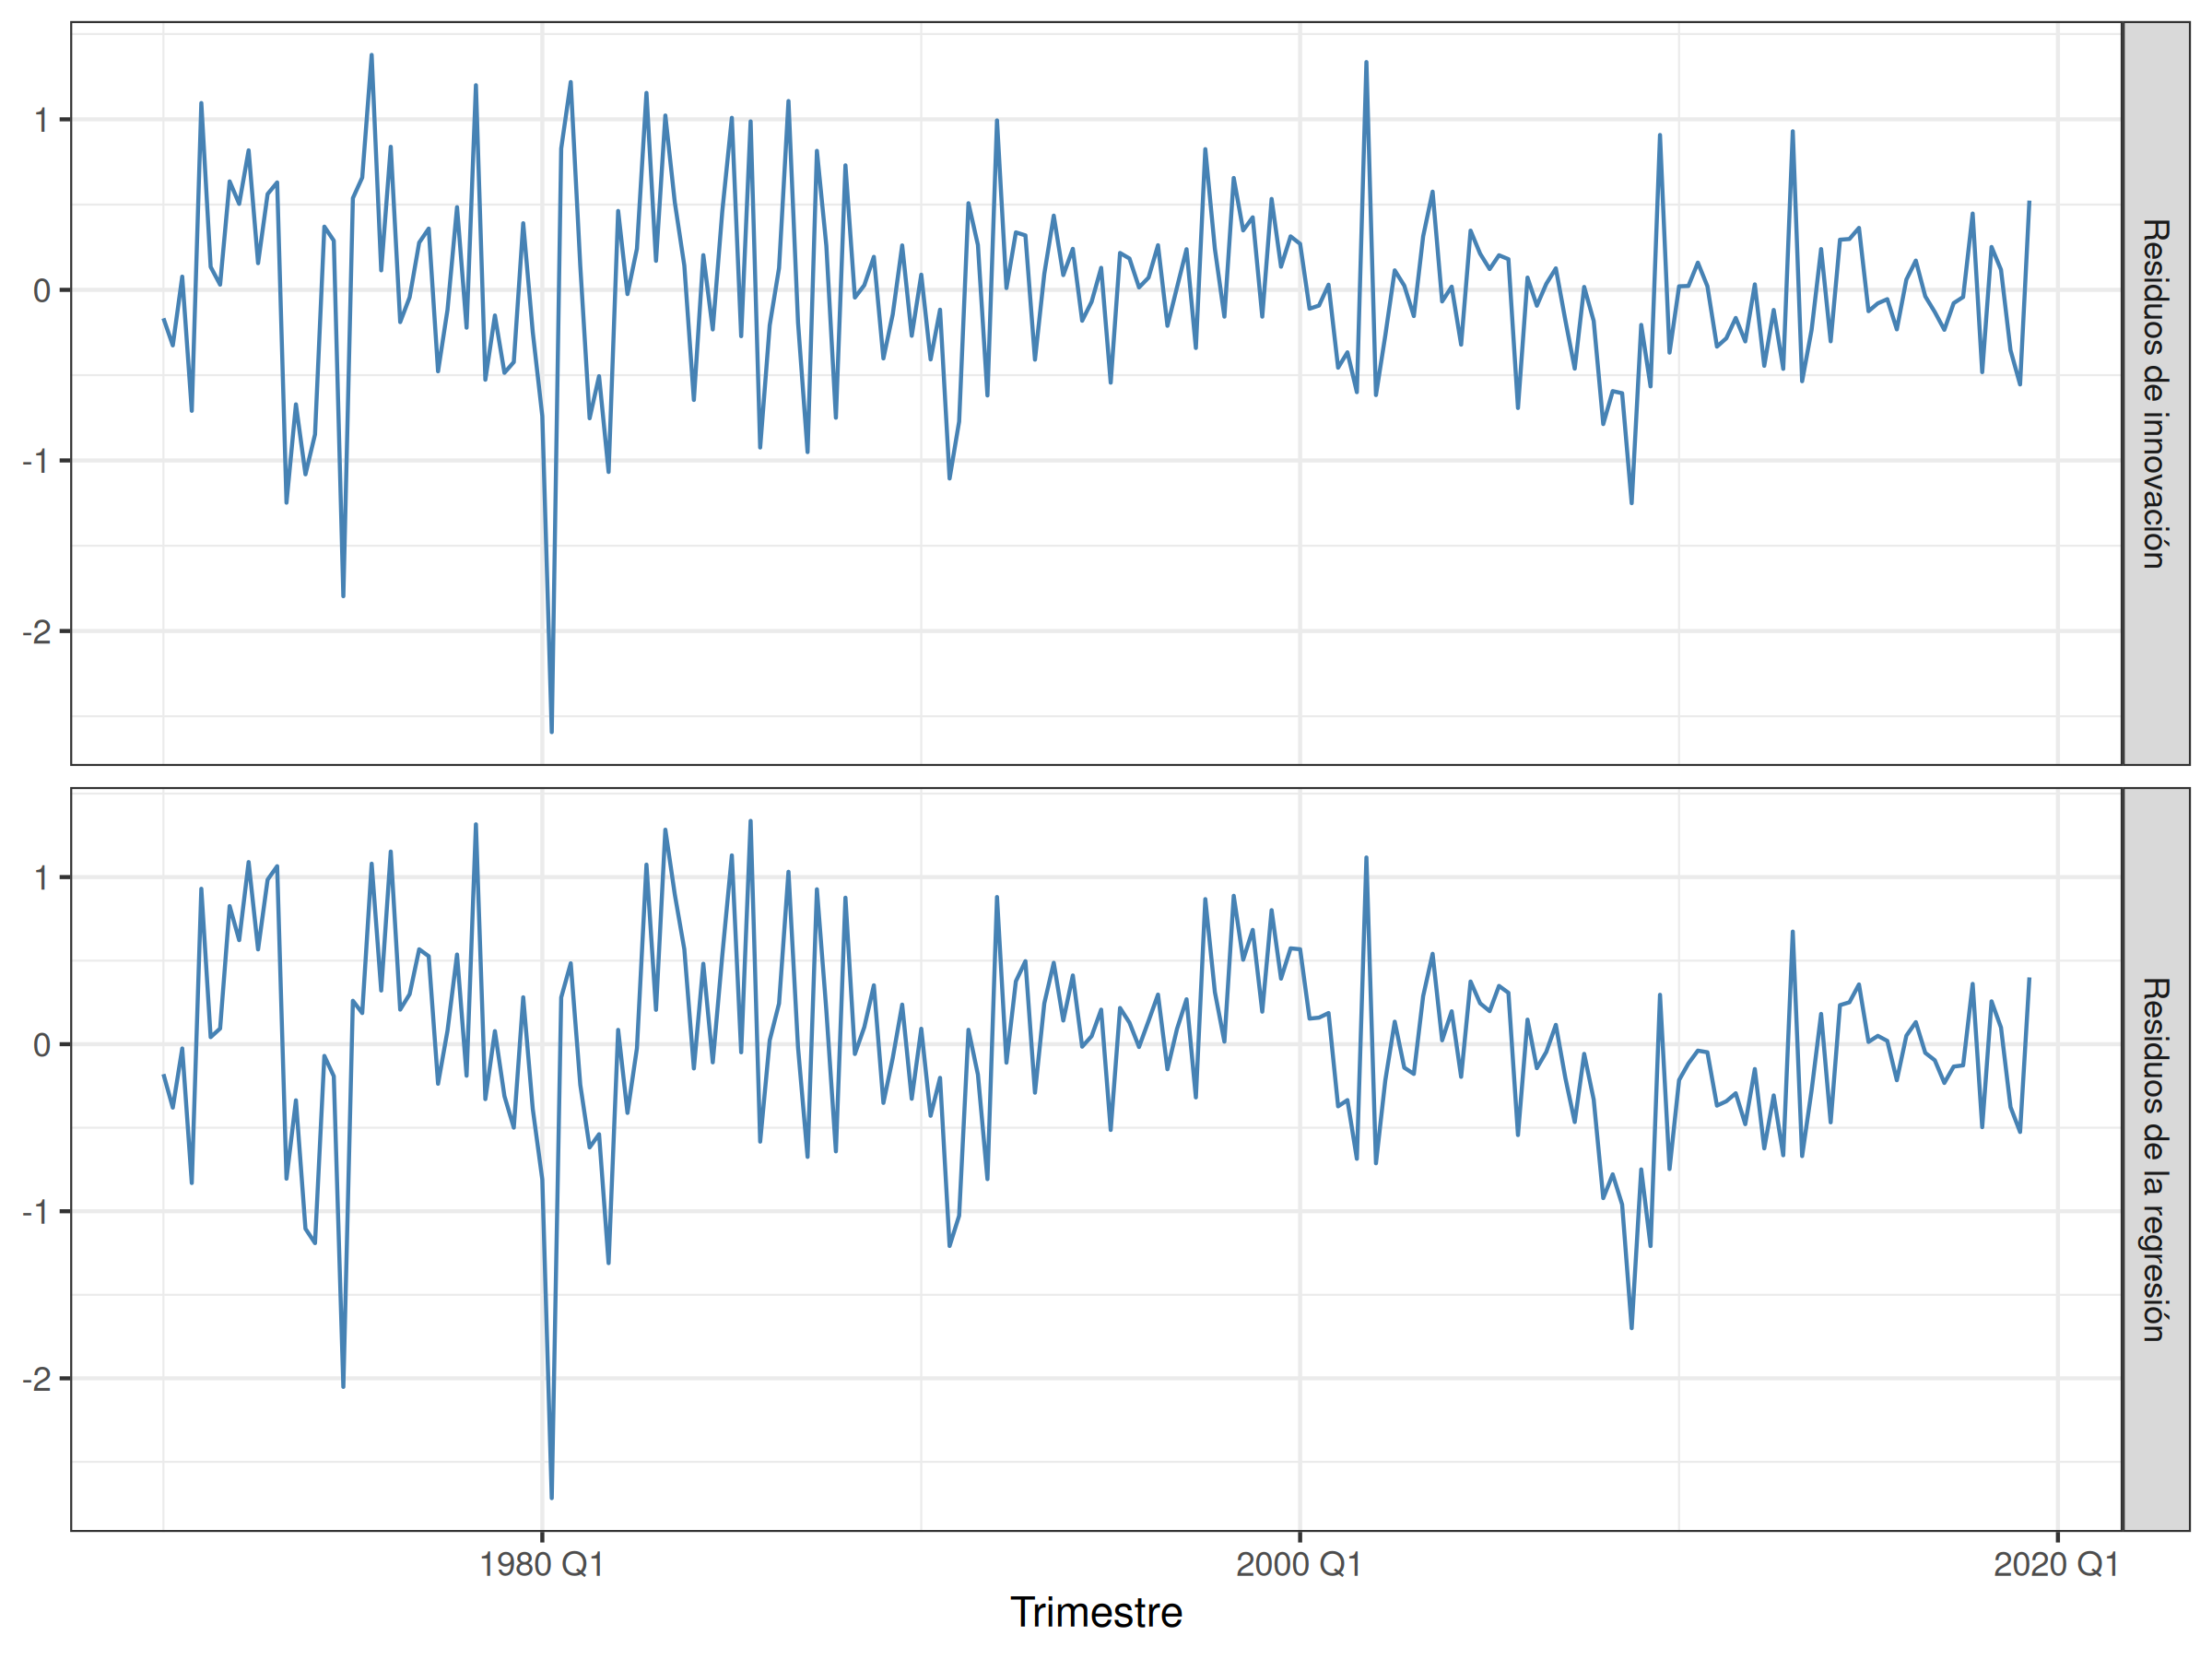

In [10]:
bind_rows(
  `Residuos de la regresión` = as_tibble(residuals(auto_arima_optimo, type = "regression")),
  `Residuos de innovación`   = as_tibble(residuals(auto_arima_optimo, type = "innovation")),
  .id = "tipo"
) |>
  ggplot(aes(ds, .resid)) +
  geom_line(colour = "steelblue") +
  facet_grid(tipo ~ ., scales = "free_y") +
  labs(x = "Trimestre", y = NULL)

## Ejemplo 3 : Gasto en publicidad por televisión y cotizaciones de seguros

Una empresa de seguro en EEUU está interesada en saber si el gasto en publicidad por televisión influye en el valor de los aportes de aseguramiento. Para ello tiene dos series de tiempo, uno con el gasto en publicidad y la otra en aportes de seguro que realiza los clientes.

In [11]:
# Datos de seguros
seguros <- read_csv("../data/insurance.csv", show_col_types = FALSE) |>
  mutate(ds = yearmonth(ds)) |>
  select(ds, Aportes = Quotes, Gasto_publicidad = TVadverts) |>
  as_tsibble(index = ds)

head(seguros)

ds,Aportes,Gasto_publicidad
<mth>,<dbl>,<dbl>
2002 ene,12.97065,7.212725
2002 feb,15.38714,9.443570
2002 mar,13.22957,7.534250
2002 abr,12.97065,7.212725
2002 may,15.38714,9.443570
2002 jun,11.72288,6.415215


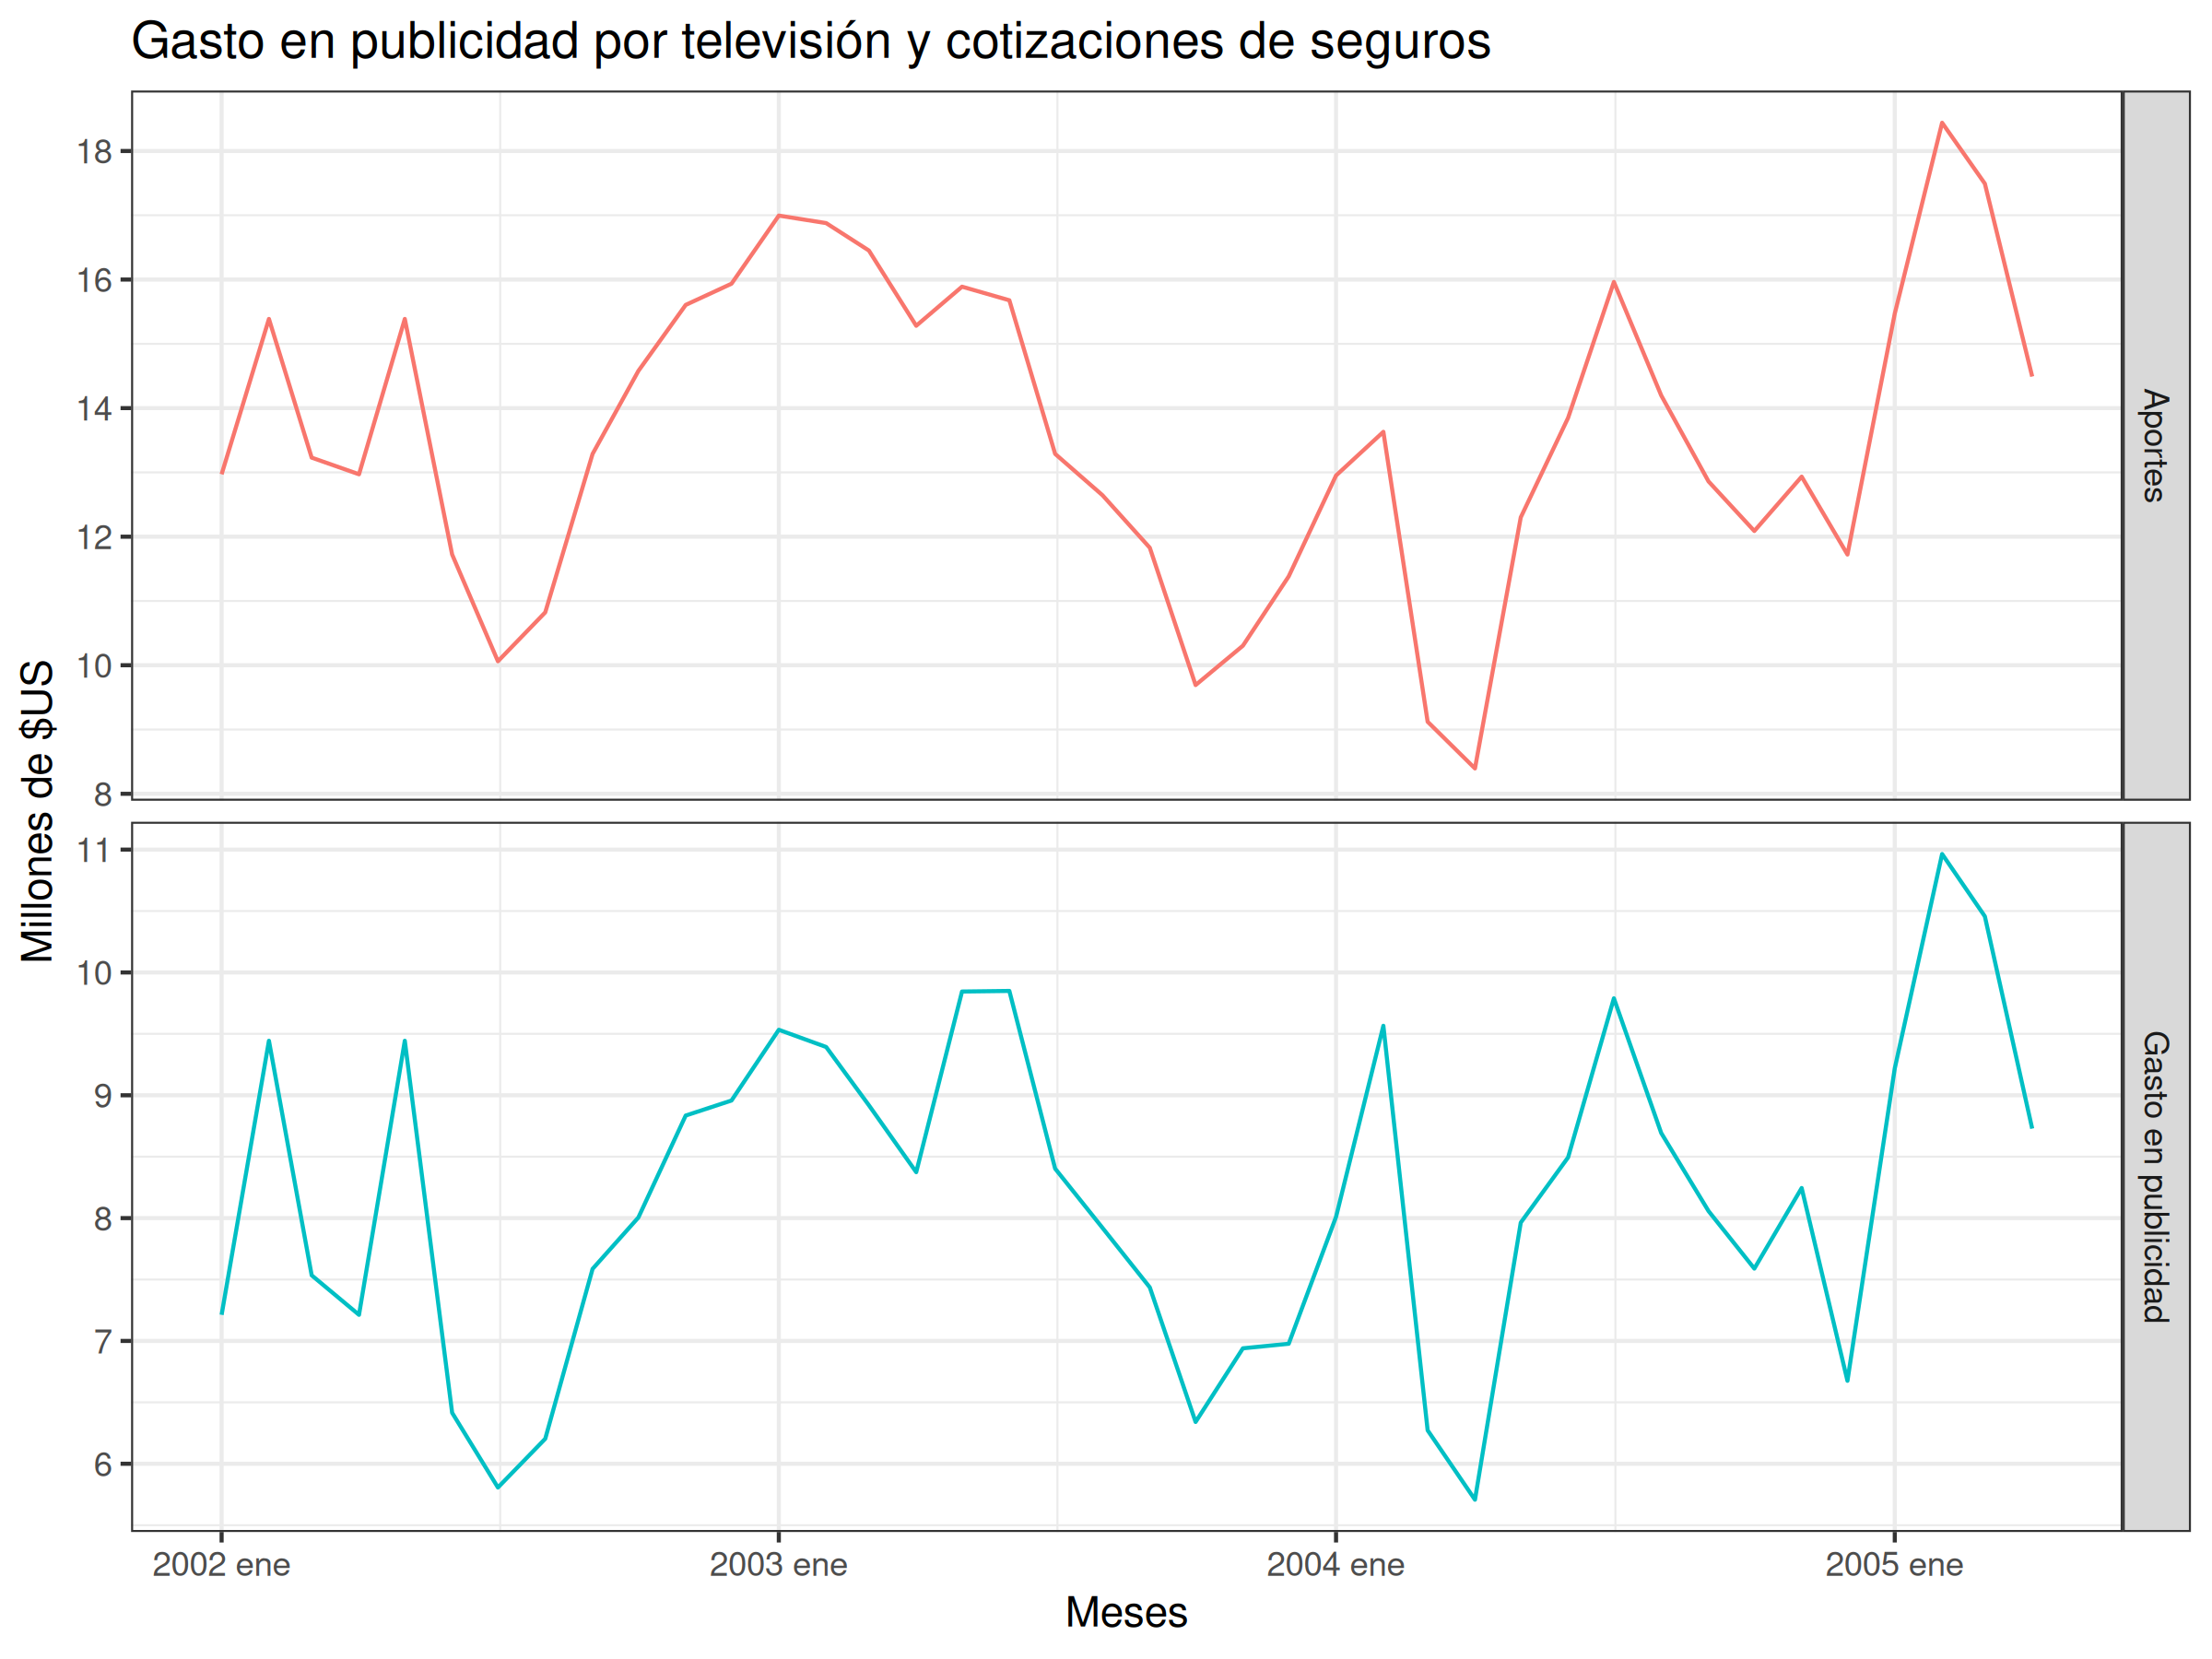

In [12]:
seguros |>
  pivot_longer(c(Aportes, Gasto_publicidad), names_to = "Serie", values_to = "valor") |>
  mutate(Serie = recode(Serie, Gasto_publicidad = "Gasto en publicidad")) |>
  ggplot(aes(ds, valor, colour = Serie)) +
  geom_line() +
  facet_grid(Serie ~ ., scales = "free_y") +
  guides(colour = "none") +
  labs(title = "Gasto en publicidad por televisión y cotizaciones de seguros",
       x = "Meses", y = "Millones de $US")

## EDA correlación series
- Correlación entre las series y sus rezagos en el gasto de publicidad  $Corr(y_t, x_{t-k})$

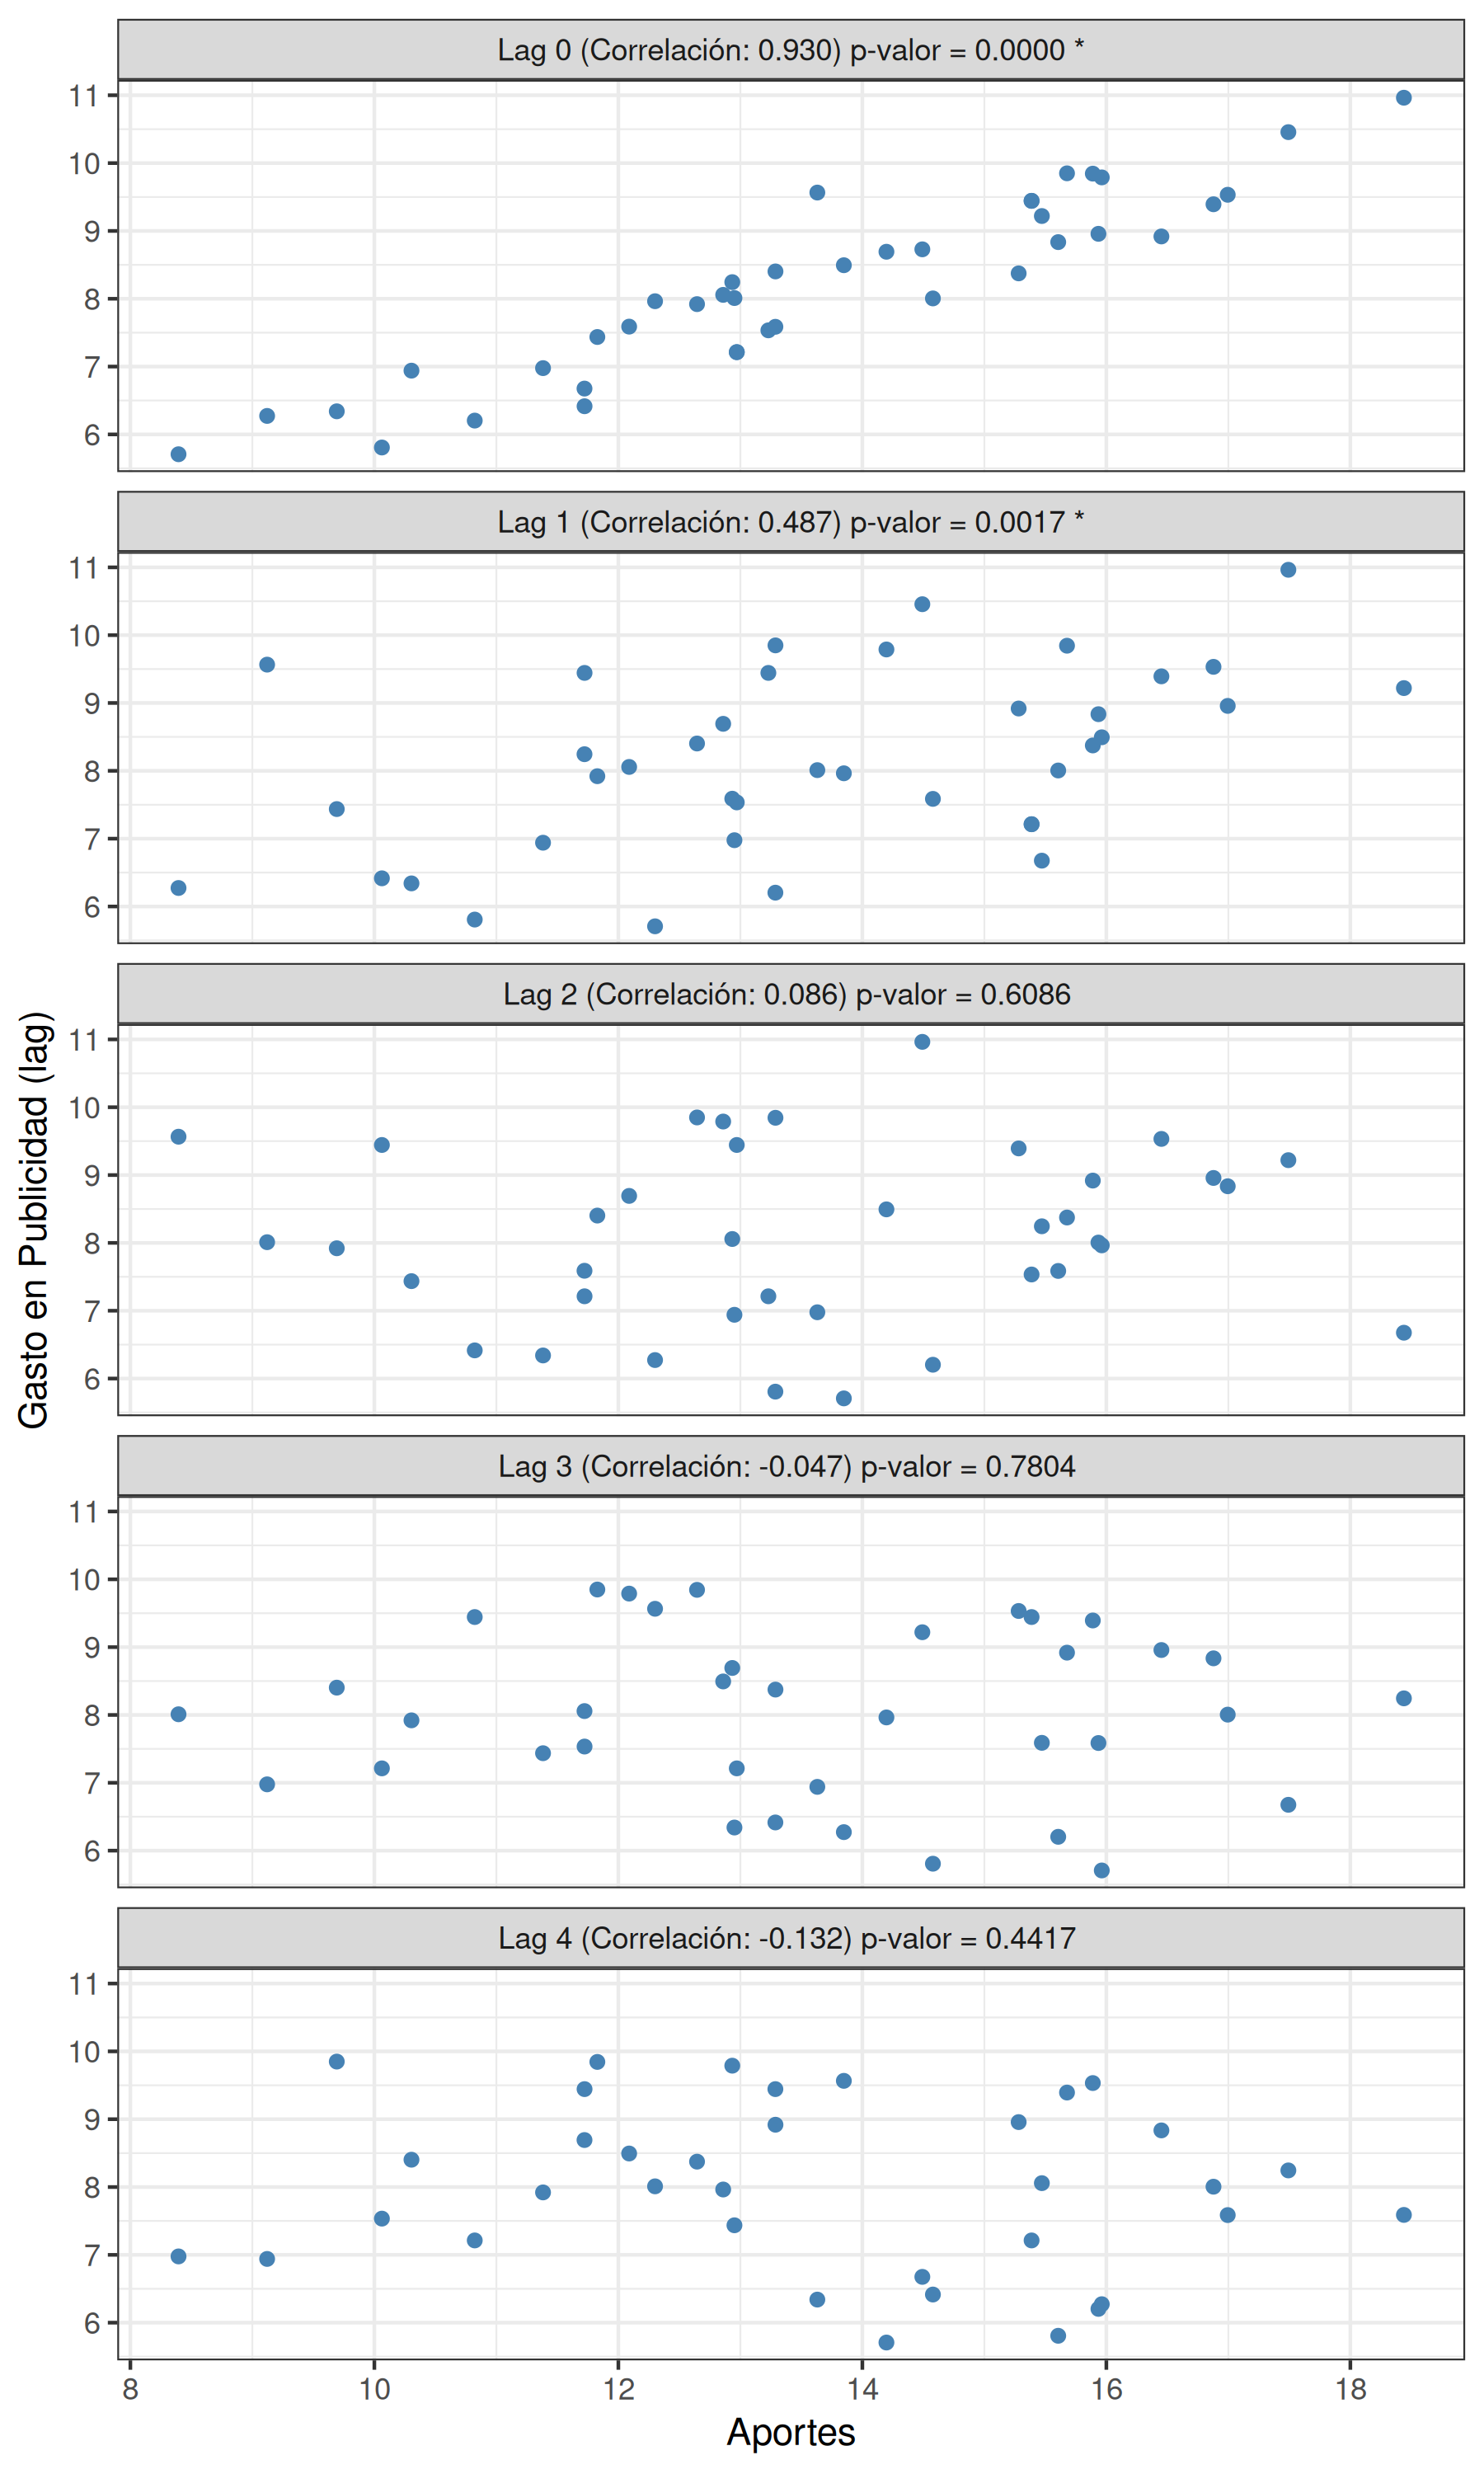

In [13]:
lags <- 0:4

datos_lags <- map_dfr(lags, \(k) {
  seguros |>
    as_tibble() |>
    mutate(gasto_lag = dplyr::lag(Gasto_publicidad, k), lag = k) |>
    filter(!is.na(gasto_lag))
})

# Correlación de Pearson y su significancia para cada rezago
etiquetas <- datos_lags |>
  group_by(lag) |>
  summarise(
    corr    = cor(Aportes, gasto_lag),
    p_valor = cor.test(Aportes, gasto_lag)$p.value
  ) |>
  mutate(texto = sprintf("Lag %d (Correlación: %.3f) p-valor = %.4f %s",
                         lag, corr, p_valor, if_else(p_valor < 0.05, "*", "")))

options(repr.plot.height = 10, repr.plot.width = 6)
datos_lags |>
  left_join(etiquetas, by = "lag") |>
  ggplot(aes(Aportes, gasto_lag)) +
  geom_point(colour = "steelblue") +
  facet_wrap(~ texto, ncol = 1) +
  labs(x = "Aportes", y = "Gasto en Publicidad (lag)")
options(repr.plot.height = 6, repr.plot.width = 8)

In [14]:
test_estacionariedad <- function(datos) {
  datos <- as.numeric(na.omit(datos))
  # Augmented Dickey-Fuller (H0: la serie tiene raíz unitaria)
  adf_result  <- suppressWarnings(adf.test(datos))
  # KPSS (H0: la serie es estacionaria en nivel)
  kpss_result <- suppressWarnings(kpss.test(datos, null = "Level"))

  # Tabla de resultados
  tibble(
    Test         = c("Prueba Augmented Dickey-Fuller (ADF)", "Prueba KPSS"),
    Estadistico  = round(c(adf_result$statistic, kpss_result$statistic), 4),
    `P-valor`    = round(c(adf_result$p.value, kpss_result$p.value), 4),
    Estacionario = c(if_else(adf_result$p.value < 0.05, "Sí", "No"),
                     if_else(kpss_result$p.value < 0.05, "No", "Sí"))
  )
}


bind_rows(
  test_estacionariedad(seguros$Gasto_publicidad) |> mutate(Serie = "Gasto publicidad", .before = 1),
  test_estacionariedad(seguros$Aportes)          |> mutate(Serie = "Aportes", .before = 1)
)

Serie,Test,Estadistico,P-valor,Estacionario
<chr>,<chr>,<dbl>,<dbl>,<chr>
Gasto publicidad,Prueba Augmented Dickey-Fuller (ADF),-2.8674,0.2330,No
Gasto publicidad,Prueba KPSS,0.1406,0.1000,Sí
Aportes,Prueba Augmented Dickey-Fuller (ADF),-2.2928,0.4586,No
Aportes,Prueba KPSS,0.1006,0.1000,Sí


**Interpretación**

- La KPSS no rechaza la estacionariedad en ninguna de las dos series, mientras que la ADF no rechaza la raíz unitaria. Con solo 40 observaciones la ADF tiene poca potencia, y los gráficos muestran series que oscilan alrededor de un nivel constante, por lo que se modelan sin diferenciar ($d = 0$).

## Modelos :

- Modelo base sin rezago

$$
Aportes_t = \beta_0 + \beta_1 Publicidad_t + \eta_t \\
\eta_t \sim \text{ARMA(p, q)}
$$

- Modelo con 1 rezago

$$
Aportes_t = \beta_0 + \beta_1 Publicidad_t + \beta_2 Publicidad_{t - 1} + \eta_t \\
\eta_t \sim \text{ARMA(p, q)}
$$

- Modelo con 2 rezagos

$$
Aportes_t = \beta_0 + \beta_1 Publicidad_t + \beta_2 Publicidad_{t - 1} + \beta_3 Publicidad_{t - 2} + \eta_t \\
\eta_t \sim \text{ARMA(p, q)}
$$

- Modelo con 3 rezagos

$$
Aportes_t = \beta_0 + \beta_1 Publicidad_t + \beta_2 Publicidad_{t - 1} + \beta_3 Publicidad_{t - 2} +  \beta_4 Publicidad_{t - 3} + \eta_t \\
\eta_t \sim \text{ARMA(p, q)}
$$

> Como nuestro objetivo es comparar modelos, es **importante mantener el mismo set de entrenamiento** o estimación entre todos los modelos. Si no, estaremos comparando modelos con diferentes ventanas de estimación.

- En `fable` los rezagos se escriben directamente en la fórmula con `lag(x, k)`. Para que todos los modelos usen la misma ventana, se dejan como `NA` las tres primeras observaciones de `Aportes` (las que se pierden con 3 rezagos).

In [15]:
# Modelos sin rezago y con rezagos 1-3, misma ventana de estimación
list_modelo_arimax <- seguros |>
  mutate(Aportes = if_else(row_number() <= 3, NA_real_, Aportes)) |>
  model(
    arimax_0 = ARIMA(Aportes ~ pdq(d = 0) + PDQ(0, 0, 0) + Gasto_publicidad),
    arimax_1 = ARIMA(Aportes ~ pdq(d = 0) + PDQ(0, 0, 0) + Gasto_publicidad +
                       lag(Gasto_publicidad)),
    arimax_2 = ARIMA(Aportes ~ pdq(d = 0) + PDQ(0, 0, 0) + Gasto_publicidad +
                       lag(Gasto_publicidad) + lag(Gasto_publicidad, 2)),
    arimax_3 = ARIMA(Aportes ~ pdq(d = 0) + PDQ(0, 0, 0) + Gasto_publicidad +
                       lag(Gasto_publicidad) + lag(Gasto_publicidad, 2) + lag(Gasto_publicidad, 3))
  )

# print modelo con tres rezagos
list_modelo_arimax |> select(arimax_3) |> report()

Series: Aportes 
Model: LM w/ ARIMA(1,0,1) errors 

Coefficients:
         ar1     ma1  Gasto_publicidad  lag(Gasto_publicidad)
      0.7567  0.6071            1.2901                 0.1323
s.e.  0.1155  0.1369            0.0656                 0.0797
      lag(Gasto_publicidad, 2)  lag(Gasto_publicidad, 3)  intercept
                       -0.1303                   -0.0643     3.6314
s.e.                    0.0759                    0.0612     1.8656

sigma^2 estimated as 0.2056:  log likelihood=-22.16
AIC=60.31   AICc=64.96   BIC=73.83


In [16]:
# Comparacion de modelos
tabla_modelos <- glance(list_modelo_arimax) |>
  select(Modelo = .model, AIC, AICc, BIC, `Log-Lik` = log_lik, sigma2) |>
  left_join(
    list_modelo_arimax |>
      pivot_longer(everything(), names_to = "Modelo", values_to = "fit") |>
      mutate(`Orden ARMA eta` = format(fit)) |>
      as_tibble() |>
      select(Modelo, `Orden ARMA eta`),
    by = "Modelo"
  ) |>
  arrange(AICc) |>
  mutate(Ranking = row_number(), .before = 1)

tabla_modelos
cat("Mejor modelo (menor AICc):", tabla_modelos$Modelo[1], " →  AICc:", tabla_modelos$AICc[1], "\n")

Ranking,Modelo,AIC,AICc,BIC,Log-Lik,sigma2,Orden ARMA eta
<int>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,arimax_1,58.08809,59.85279,66.53249,-24.04404,0.2094368,"<LM w/ ARIMA(1,0,1) errors>"
2,arimax_2,60.03254,62.57799,70.16581,-24.01627,0.2150429,"<LM w/ ARIMA(1,0,1) errors>"
3,arimax_3,60.31461,64.95977,73.82565,-22.15731,0.2056454,"<LM w/ ARIMA(1,0,1) errors>"
4,arimax_0,66.56420,68.32890,75.00859,-28.28210,0.2649757,"<LM w/ ARIMA(2,0,0) errors>"


Mejor modelo (menor AICc): arimax_1  →  AICc: 59.85279 


## Selección mejor modelo

- El mejor modelo (con el valor de AICc más pequeño) es el de 1 rezago; es decir, incluye la publicidad únicamente en el mes actual y en el mes anterior. Por lo tanto, ahora reestimamos ese modelo, pero utilizando todos los datos disponibles.

In [17]:
# Estimacion del modelo final con todos los datos
mejor_arimax_lag <- seguros |>
  model(ARIMA(Aportes ~ pdq(d = 0) + PDQ(0, 0, 0) + Gasto_publicidad + lag(Gasto_publicidad)))

# resultados
report(mejor_arimax_lag)

Series: Aportes 
Model: LM w/ ARIMA(1,0,2) errors 

Coefficients:
         ar1     ma1     ma2  Gasto_publicidad  lag(Gasto_publicidad)
      0.5123  0.9169  0.4591            1.2527                 0.1464
s.e.  0.1849  0.2051  0.1895            0.0588                 0.0531
      intercept
         2.1554
s.e.     0.8595

sigma^2 estimated as 0.2166:  log likelihood=-23.94
AIC=61.88   AICc=65.38   BIC=73.7


**Interpretación**

$$
Aportes_t = 2.1554 + 1.2527\, Publicidad_t + 0.1464\, Publicidad_{t - 1} + \eta_t \\
\eta_t = 0.5123\, \eta_{t-1} + \varepsilon_t + 0.9169\, \varepsilon_{t-1} + 0.4591\, \varepsilon_{t-2} \\
\varepsilon_t \sim WN(0,\ 0.2166)
$$

- Intercepto (2.16): Si no hubiera inversión en publicidad hoy ni ayer, se esperarían en promedio aproximadamente 2.16 unidades de aportes.
- Efecto inmediato del gasto en publicidad (1.26): Por cada unidad que aumente el gasto en publicidad hoy, los aportes aumentan en promedio 1.25 unidades.
- Efecto retardado del gasto en publicidad (0.15): El gasto en publicidad del mes anterior aún tiene un efecto positivo residual en los aportes actuales.
- Error de la regresión ($\eta_t$): Representa todo lo que afecta a los aportes que no es publicidad (ruido, competencia, etc.). Sigue un $ARMA(1, 2)$: el error de hoy depende del error del mes anterior y de los choques aleatorios de los dos meses previos.

.model,lb_stat,lb_pvalue
<chr>,<dbl>,<dbl>
"ARIMA(Aportes ~ pdq(d = 0) + PDQ(0, 0, 0) + Gasto_publicidad + lag(Gasto_publicidad))",3.086253,0.87691


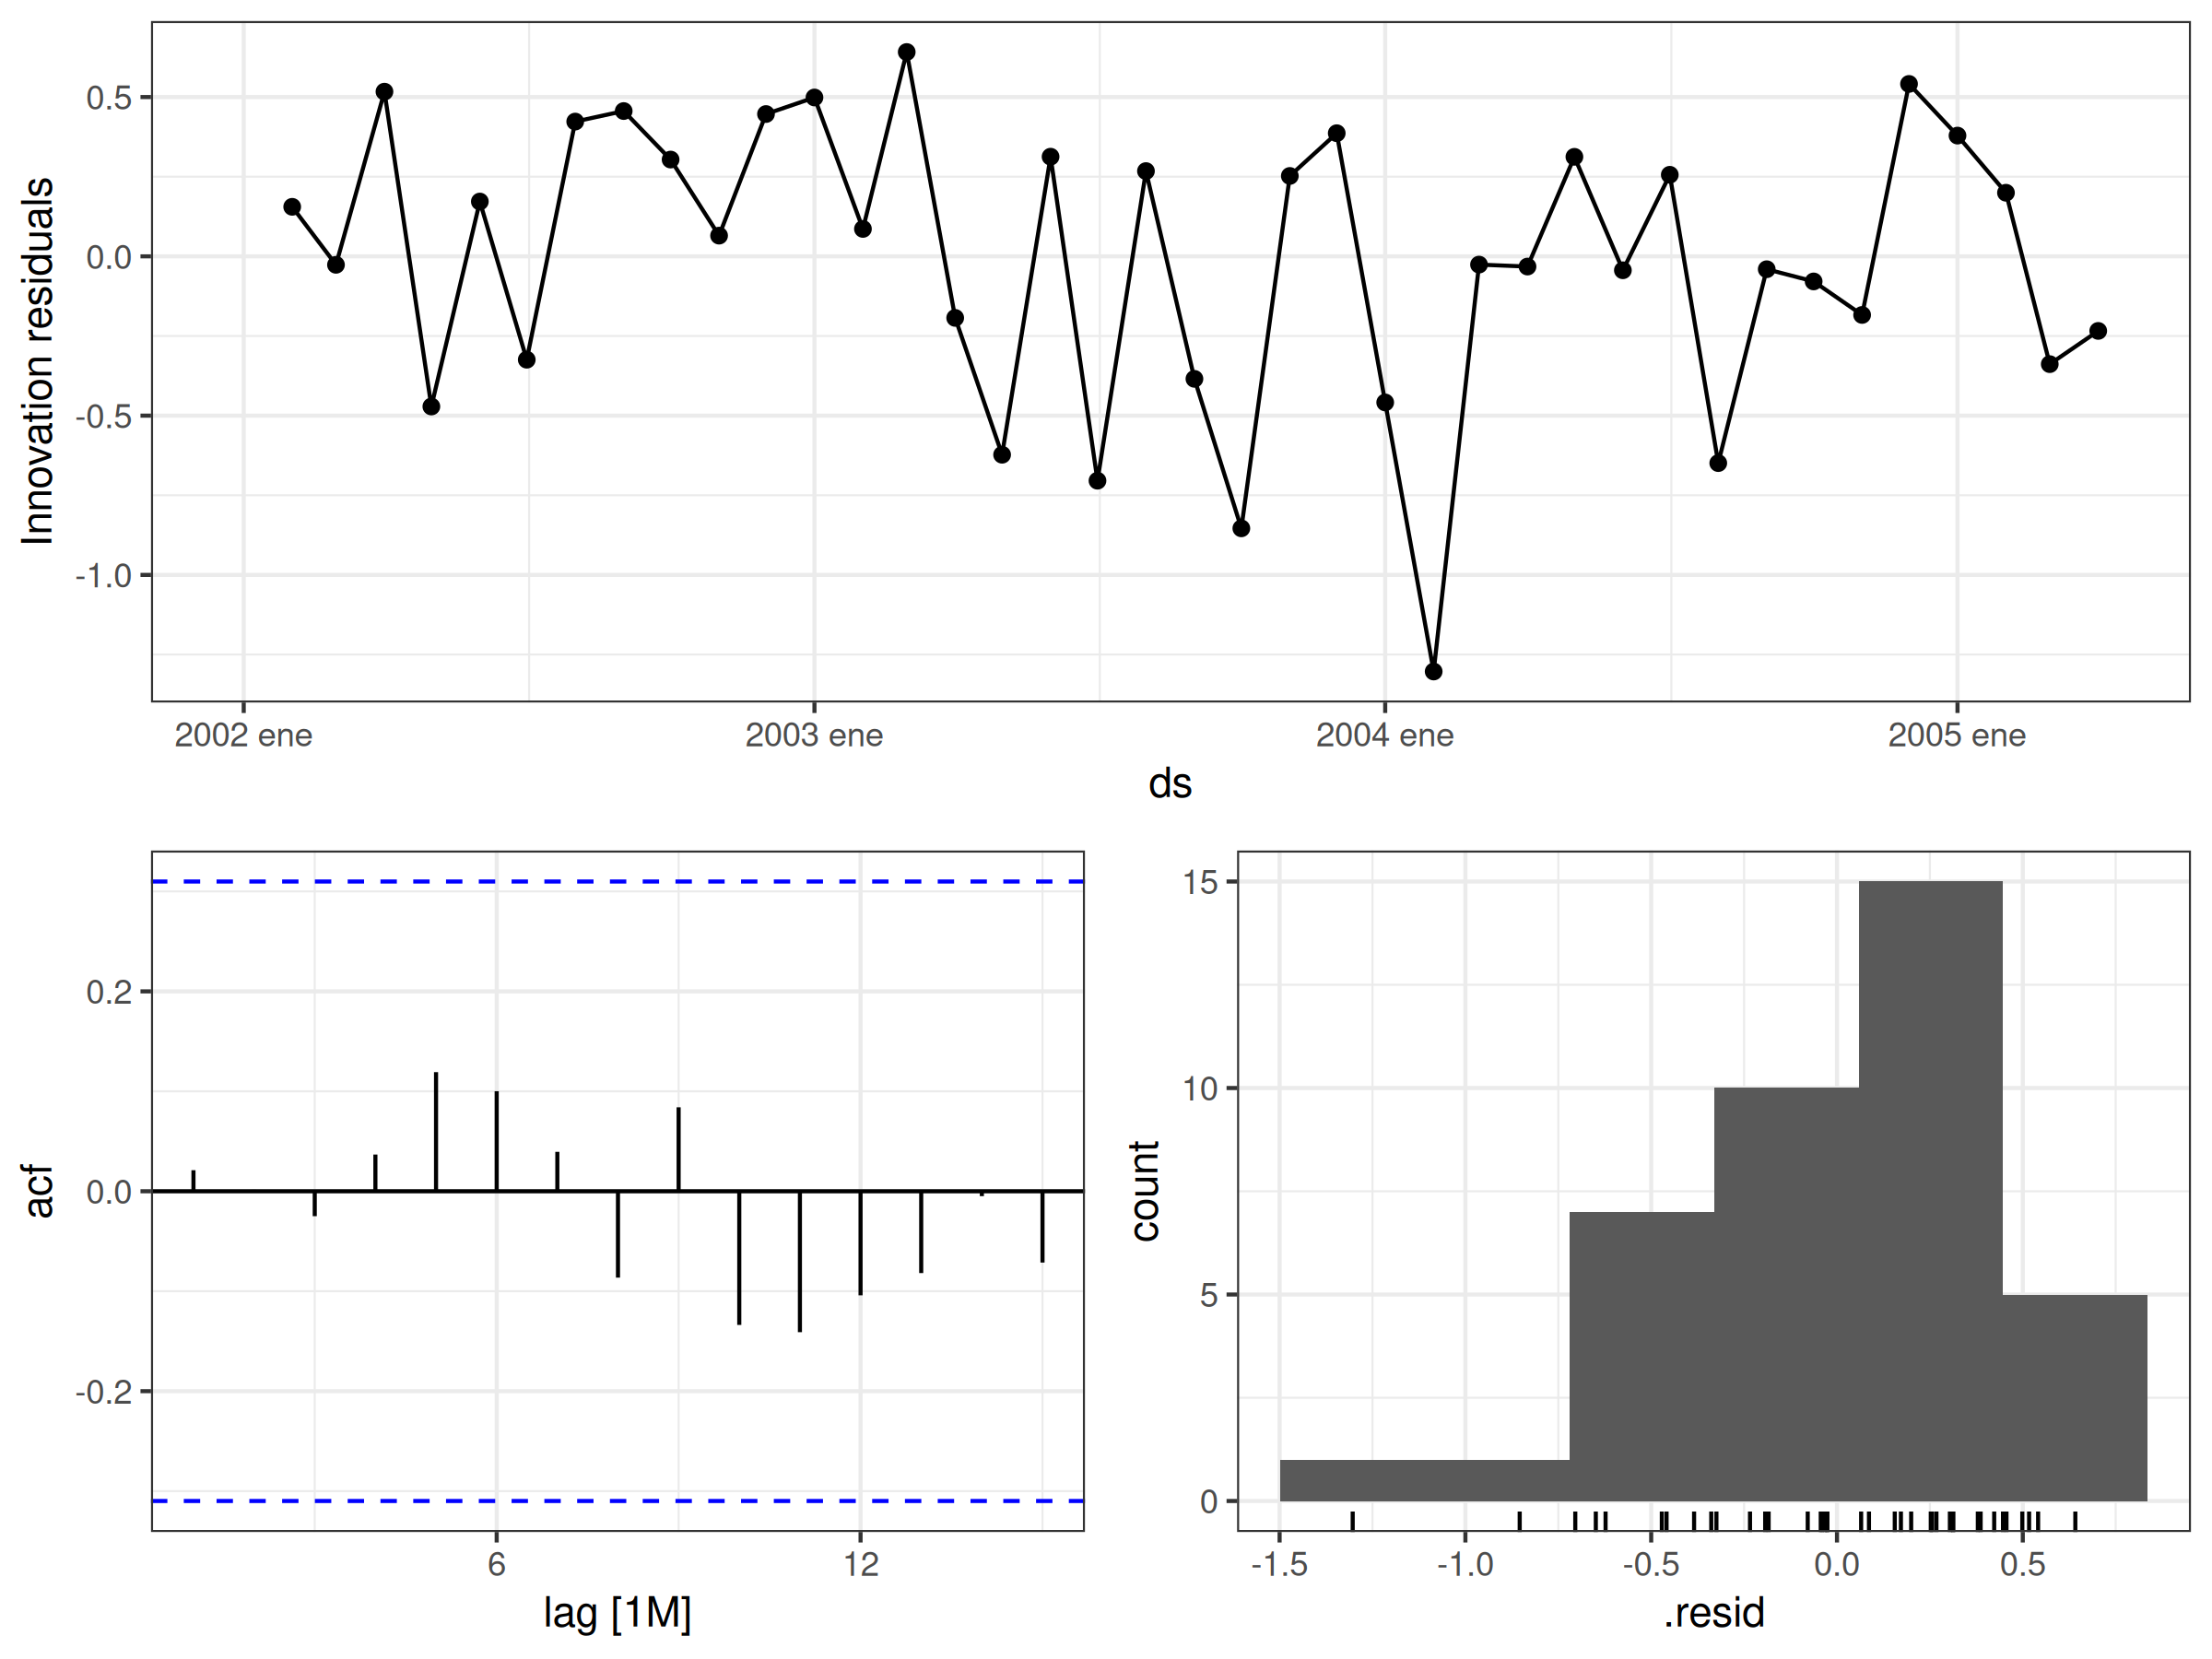

In [18]:
# Verificar ruido blanco
# Diagnostico del modelo
# (el primer residuo es NA porque se pierde una observación con el rezago)
suppressWarnings(print(mejor_arimax_lag |> gg_tsresiduals()))

augment(mejor_arimax_lag) |>
  features(.innov, ljung_box, lag = 10, dof = 3)

## Pronósticos
- Podemos calcular pronósticos utilizando este modelo si asumimos valores futuros para la variable de publicidad.
- Si fijamos la publicidad mensual futura en 8 unidades ¿Cúal sera el efecto en los aportes esperados en 8 meses?
- `new_data()` crea las fechas futuras y en ellas fijamos el gasto en publicidad. `fable` calcula el rezago `lag(Gasto_publicidad)` usando también el último dato observado.

Fecha,Pronóstico,IC Inferior,IC Superior
<mth>,<dbl>,<dbl>,<dbl>
2005 may,13.01859,12.10639,13.93080
2005 jun,13.01693,11.42573,14.60812
2005 jul,13.17819,11.25128,15.10509
2005 ago,13.26080,11.25507,15.26653
2005 sep,13.30313,11.27722,15.32904
2005 oct,13.32481,11.29364,15.35599
2005 nov,13.33592,11.30337,15.36847
2005 dic,13.34161,11.30870,15.37453


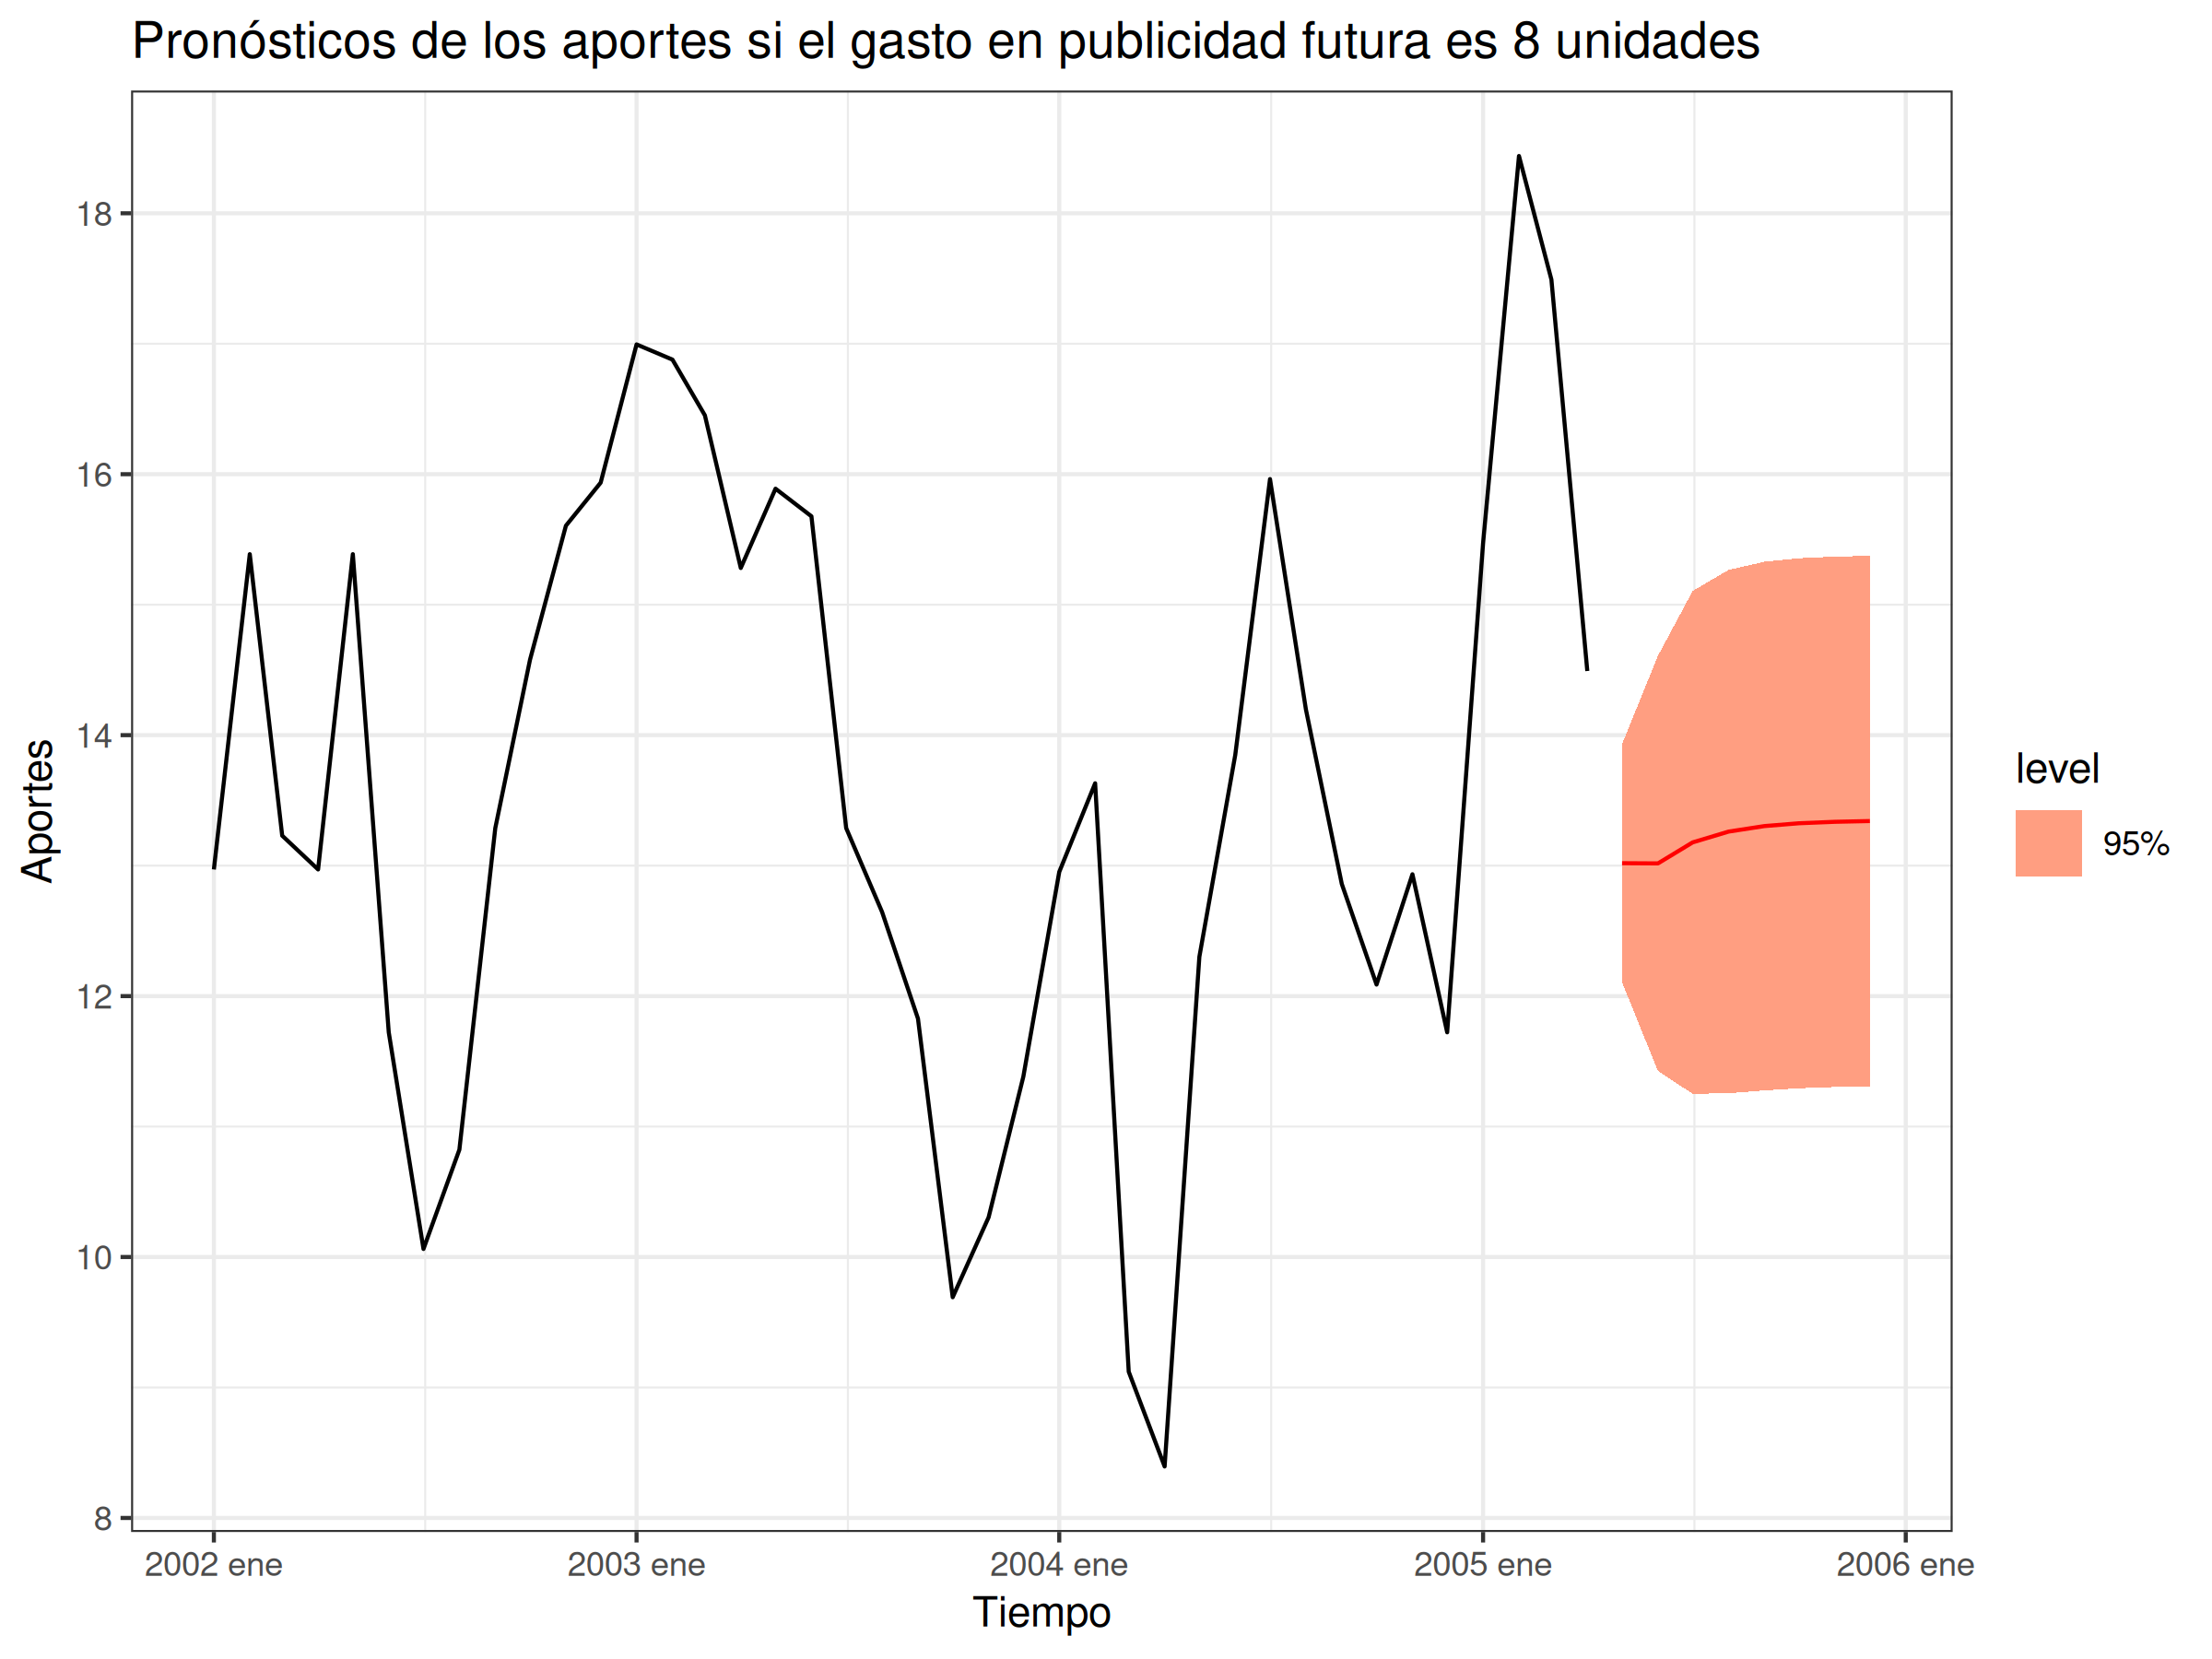

In [19]:
# Pronostico de los proximos 8 meses con la publicidad fijada en 8
gasto_publicidad_pronostico <- new_data(seguros, 8) |>
  mutate(Gasto_publicidad = 8)

pronostico <- mejor_arimax_lag |>
  forecast(new_data = gasto_publicidad_pronostico)

# Graficar
pronostico |>
  autoplot(seguros, level = 95, colour = "red", linetype = "dashed") +
  labs(x = "Tiempo", y = "Aportes",
       title = "Pronósticos de los aportes si el gasto en publicidad futura es 8 unidades")

# Tabla de pronóstico
pronostico |>
  hilo(level = 95) |>
  unpack_hilo(`95%`) |>
  as_tibble() |>
  select(Fecha = ds, `Pronóstico` = .mean, `IC Inferior` = `95%_lower`, `IC Superior` = `95%_upper`)